# Where a coding ban takes effect in Qwen3-8B: route-test analysis demo

A prompt ban such as *"Do not use a full sort for this task."* makes Qwen3-8B (bf16, thinking off) write a different algorithm. This artifact asks **which internal route carries that effect**, on the 12 frozen bench coding tasks of exp11.

The arms of a *CRN slot* (task, template, k) are sampled with the **same uniforms**: common random numbers with inverse-CDF sampling. They differ only in the KV cache that the generated tokens read:

| arm | cache read by the generated tokens | tests |
|---|---|---|
| a | full ban prompt | endpoint (clean) |
| b | token-length-matched neutral twin (*"Do not use fire for this task. . . ."*) | endpoint (corrupted) |
| c | twin condition segment + ban task-spec states (KV splice at `p1`) | **prompt route**: are the later prompt states enough? |
| d | ban condition segment + twin task-spec states | **direct route**: is reading the ban itself enough? |
| K0 | full ban, with the condition span dropped from the cache | removal of the direct route |

The frozen labellers labelled each generated program with its mechanism: runtime trace first, then AST, then a blind LLM judge on disagreement. For a task with default mechanism D, $s_X$ is the share of attempts in arm X labelled D, and

$$F_\text{prompt}=\frac{s_b-s_c}{s_b-s_a},\qquad F_\text{direct}=\frac{s_b-s_d}{s_b-s_a},\qquad I = 1-F_\text{prompt}-F_\text{direct},\qquad F_{K0}=\frac{s_b-s_{K0}}{s_b-s_a}.$$

**What this notebook runs.** The sampling stage (`method.py gpu`) cannot run in a 10-minute Colab session: it made 13,030 Qwen3-8B generations on an NVIDIA L4 in about 1.8 GPU-hours, followed by the labellers and an LLM judge. Instead, the notebook loads **500 real labelled samples** from that stage: 100 CRN slots (5 gated tasks × 5 ban templates × slots k = 0–3), each with all five arms. It then runs the artifact's **CPU code** on them, essentially unchanged:

- `src/analysis/analysis.py` (stage `method.py analysis`, S9): shares, route fractions, hierarchical bootstrap, jackknife and BCa intervals, the C2a verdict, CRN flip tables, first divergence, landing by route, and C2c;
- `tests/test_cpu.py` (stage `method.py tests`): the inverse-CDF redraw test T4, the estimator-recovery test T5 and the n-gram rule test T3;
- the protocol constants and utilities of `src/cfg.py`, the prompt builder of `src/prompts_s1.py` and the CRN uniform stream of `src/engine.py`.

The original reads some inputs from files: `results/gate.json`, `predictions/ngrams.json`, `predictions/c2c.json` and the bench specs. Here they come from the same `mini_demo_data.json`, together with the full-run numbers that the results section compares against.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT pre-installed on Colab, always install (the original analysis logs with it)
_pip('loguru==0.7.3')

# numpy, scipy, pandas, statsmodels, matplotlib — pre-installed on Colab, install locally only at Colab's versions
# (the artifact itself pinned numpy 2.2.6, scipy 1.18.1, pandas 3.0.6, statsmodels 0.15.0, matplotlib 3.11.2)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'pandas==2.2.2', 'statsmodels==0.14.6', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# original imports (src/analysis/analysis.py, plus hashlib / json from src/cfg.py)
import collections
import hashlib
import json
import math
import sys
from pathlib import Path
from typing import Any

import numpy as np
from loguru import logger
from scipy import stats

# notebook additions: timing, tables and figures
import time

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
import warnings

# output hygiene: hide two expected warnings from bootstrap resamples (a task whose s_b - s_a is 0 gives an
# all-NaN slice in the *_mean variants; tied resampled points make Spearman undefined); the original logged them
warnings.filterwarnings("ignore", message="Mean of empty slice", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=stats.ConstantInputWarning)

T_START = time.time()

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_5eGZGmskluur/round-3/experiment-16/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
meta = data["metadata"]
examples = data["datasets"][0]["examples"]
print(meta["method_name"])
print(f"model {meta['model']} @ {meta['model_revision'][:10]}, {meta['dtype']}, thinking={meta['thinking']}; {meta['decoding']}")
print(f"dataset '{data['datasets'][0]['dataset']}': {len(examples)} CRN slots x {len(meta['demo_subset']['arms'])} arms "
      f"= {meta['demo_subset']['n_samples']} labelled samples; tasks {meta['demo_subset']['tasks']}, "
      f"slots k = {meta['demo_subset']['slots_k']}")
print("example 0 input: ", examples[0]["input"])
print("example 0 labels: a =", examples[0]["output"], "|", {a: examples[0][f"predict_{a}"] for a in ("b", "c", "d", "K0")})

GitHub data unavailable, using local mini_demo_data.json: <urlopen error [Errno 111] Connection refused>
Bench route test of prompt bans (CRN KV-splice arms, one-shot veto, prefill) in Qwen3-8B
model Qwen/Qwen3-8B @ b968826d9c, bfloat16, thinking=False; T=1.0, top-p 1.0, no top-k, max 1024 new tokens, CRN inverse-CDF sampling
dataset 'route_arms': 100 CRN slots x 5 arms = 500 labelled samples; tasks ['T03', 'T06', 'T05', 'T10', 'T13'], slots k = [0, 1, 2, 3]
example 0 input:  task T03 | template W1 | slot k=0 | ban segment: 'Do not use a full sort for this task.' | neutral twin: 'Do not use man for this task. . .'
example 0 labels: a = quickselect | {'b': 'full_sort|pass', 'c': 'quickselect|pass', 'd': 'quickselect|pass', 'K0': 'quickselect|pass'}


## Configuration

All tunable parameters are in one place.

- `N_SLOTS` sets how much of the demo data is used. The full run had 20 CRN slots per template and 12 tasks, i.e. 100 slots per task and arm, which only the GPU stage can produce.
- The resampling sizes are set to the artifact's **original values**, which take well under a minute here. The smallest quick-look setting used while testing is noted in the cell.

In [5]:
# ---- data subset ----
N_SLOTS = 4                    # CRN slots per template taken from mini_demo_data.json (it holds k = 0..3; full run: 20)
SHOW_SLOT = ("T06", "W1", 1)   # CRN slot whose five programs are printed below

# ---- resampling sizes: the artifact's original full-run values (the whole notebook still runs in well under a minute)
N_BOOT = 10000                 # pooled hierarchical task -> template -> slot bootstrap reps (cfg.N_BOOT)
N_BOOT_TASK = 4000             # per-task template -> slot bootstrap reps (per_task_route default)
N_PERM = 100000                # permutations for the one-sided C2c Spearman test (cfg.N_PERM)
N_RHO_BOOT = 4000              # task bootstrap reps for the C2c rho interval (c2c_analysis)
LANDING_NULL_REPS = 2000       # resampling-null reps for the landing-by-route JS divergence (landing_null default)
T4_N_DRAWS = 200_000           # draws in CPU test T4 (t4 default)
T5_N_SETS = 200                # simulated datasets in CPU test T5 (t5 default)
T5_N_BOOT = 1000               # bootstrap reps per simulated dataset in T5 (t5 default)
# smallest quick-look setting used while testing: N_SLOTS = 1; N_BOOT = N_BOOT_TASK = N_PERM = N_RHO_BOOT =
# LANDING_NULL_REPS = 100; T4_N_DRAWS = 10_000; T5_N_SETS = 2; T5_N_BOOT = 10
RNG_SEED = 20261020            # cfg.RNG_SEED; every bootstrap / permutation stream is RNG_SEED + a fixed offset
RESULTS_DIR = Path("demo_results")  # where the analysis JSON files are written (original: results/)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

## Protocol constants and utilities (`src/cfg.py`)

These are the frozen protocol values from `src/cfg.py`:

- the 12 Stage-A bench tasks and their default mechanisms;
- the five ban templates W1–W5, each with ban, mention and neutral wording (from the shared protocol v2);
- the pre-registered decision thresholds;
- the small utilities the analysis uses.

`stable_seed()` is byte-for-byte exp8's, so the uniforms of every CRN slot can be re-derived. The original's file paths (`ROOT / "results"`, `inputs/`, …) are dropped, because their contents come from `data`.

In [6]:
# ------------------------------------------------------------------------------------------------ model
MODEL_ID = "Qwen/Qwen3-8B"
MODEL_REVISION = "b968826d9c46dd6066d109eabc6255188de91218"
N_LAYERS = 36
IM_END = 151645
ENDOFTEXT = 151643
MAX_NEW_TOKENS = 1024
TEMPERATURE = 1.0
DECODING = "T1.0_topp1.0_topk-off_max1024_thinkoff"
TEMPLATE_TAIL = "<|im_end|>\n<|im_start|>assistant\n<think>\n\n</think>\n\n"
BATCH = 20  # constant batch shape for every sampled batch (two CRN blocks of 10); see deviations

# ------------------------------------------------------------------------------------------------ bench
STAGE_A = ["T03", "T04", "T06", "T05", "T10", "R1", "T08", "R3", "T13", "R6", "T14", "T11"]
TASK_DIR = {"T03": "T03_kth_smallest", "T04": "T04_substring_search", "T06": "T06_find_duplicate",
            "T05": "T05_two_sum", "T10": "T10_connected_components", "R1": "R1_non_overlapping_intervals",
            "T08": "T08_fibonacci", "R3": "R3_topological_order", "T13": "T13_merge_intervals",
            "R6": "R6_first_last_position", "T14": "T14_top_k_frequent", "T11": "T11_longest_increasing_subsequence"}
DEFAULT = {"T03": "full_sort", "T04": "naive", "T06": "hash_set", "T05": "hash_map", "T10": "union_find",
           "R1": "greedy_end", "T08": "iteration", "R3": "kahn", "T13": "sort_sweep", "R6": "binary_search",
           "T14": "sort_by_count", "T11": "quadratic_dp"}
PATH_TASKS = ("t1", "t2")
PATH_DEFAULT = {"t1": "bfs", "t2": "dijkstra"}
PATH_SUB = {"t1": "dfs", "t2": "bf_spfa"}
ALL_TASKS = STAGE_A + list(PATH_TASKS)

# W1-W5 (ban, mention, neutral) verbatim from the shared protocol v2 (exp8 cfg.TEMPLATES).
TEMPLATES: dict[str, tuple[str, str, str]] = {
    "W1": ("Do not use {X} for this task.", "You could use {X} for this task.", "Do not use {N} for this task."),
    "W2": ("Your solution must not rely on {X}.", "Your solution may rely on {X}.", "Your solution must not rely on {N}."),
    "W3": ("Avoid {X} entirely.", "Consider {X} first.", "Avoid {N} entirely."),
    "W4": ("{X} is not allowed here.", "{X} is allowed here.", "{N} is not allowed here."),
    "W5": ("Write a correct solution that does not use {X}.", "Write a correct solution that may use {X}.",
           "Write a correct solution that does not use {N}."),
}
TEMPLATE_IDS = list(TEMPLATES.keys())
FILLER = " ."  # exp7 frozen neutral-twin padding filler
N_PER_TEMPLATE = 20
BLOCK = 10

THRESHOLDS = {
    "F_confirm": 2.0 / 3.0, "F_ci_lower": 0.5, "F_direct_disconfirm": 1.0 / 3.0,
    "gate_avoidance": 0.5, "gate_min_nondefault": 20,
    "veto_low_direct": 0.8, "veto_high_direct": 0.5, "pred_low_direct_F": 0.15, "pred_high_direct_F": 0.25,
    "veto_min_fire_rate": 0.5, "c2c_hit_fraction": 2.0 / 3.0, "c2c_disconfirm_hit": 0.5, "c2c_alpha": 0.05,
    "ngram_presence": 0.8, "coveto": 0.5, "reemerge": 0.2, "screen_min_nond": 20, "placebo_tol": 0.1,
    "c2b_eligible_V": 0.5, "c2b_task_share": 2.0 / 3.0,
}
# N_BOOT, N_PERM and RNG_SEED are set in the configuration cell (cfg.py: 10000, 100000, 20261020)


# ------------------------------------------------------------------------------------------------ utils
def setup_logging(name: str) -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    # the original also logs to a file: logger.add(str(LOG_DIR / f"{name}.log"), rotation="30 MB", level="DEBUG")


def stable_seed(*parts: Any) -> int:
    """exp8: deterministic 63-bit seed from arbitrary parts (sha256 of their '|'-joined repr)."""
    return int(hashlib.sha256("|".join(str(p) for p in parts).encode()).hexdigest(), 16) % (2 ** 63)


def _json_default(o: Any) -> Any:
    try:
        import numpy as np

        if isinstance(o, np.integer):
            return int(o)
        if isinstance(o, np.floating):
            return None if not np.isfinite(o) else float(o)
        if isinstance(o, np.ndarray):
            return o.tolist()
        if isinstance(o, np.bool_):
            return bool(o)
    except ImportError:
        pass
    if isinstance(o, Path):
        return str(o)
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    if isinstance(o, tuple):
        return list(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def _finite(o: Any) -> Any:
    if isinstance(o, float):
        return o if math.isfinite(o) else None
    if isinstance(o, dict):
        return {str(k): _finite(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_finite(v) for v in o]
    return o


def write_json(p: Path, obj: Any, indent: int | None = 1) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    tmp.write_text(json.dumps(_finite(obj), indent=indent, default=_json_default))
    tmp.replace(p)


def wilson_ci(k: int, n: int, z: float = 1.959963984540054) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))


def cap_first(s: str) -> str:
    return s[:1].upper() + s[1:] if s else s


def default_of(task: str) -> str:
    return PATH_DEFAULT[task] if task in PATH_TASKS else DEFAULT[task]


setup_logging("analysis")
print(f"{len(STAGE_A)} bench tasks, templates {TEMPLATE_IDS}; model {MODEL_ID} ({DECODING})")

12 bench tasks, templates ['W1', 'W2', 'W3', 'W4', 'W5']; model Qwen/Qwen3-8B (T1.0_topp1.0_topk-off_max1024_thinkoff)


## The prompts: a ban and its token-length-matched neutral twin (`src/prompts_s1.py`)

Each bench prompt is `cap_first(condition) + blank line + task spec`, wrapped in Qwen3's chat template with an empty think block.

- The **ban** condition fills template W*w* with the display name of the task's default mechanism.
- The **twin** condition replaces it with a neutral noun and pads with `' .'` until both prompts have the same token length.

Stage S1 asserted, for every (task, template), that the two prompts differ only inside the condition segment `[p0, p1)`. That segment runs from token 3 to the first token of `Task:`. So a KV cache can be spliced at `p1`:

- arm **c** reads twin positions `[0, p1)` and ban positions `[p1, P)` (the task spec *after* reading the ban), with the ban's next-token logits;
- arm **d** reads ban positions `[0, p1)` and twin positions `[p1, P)`, with the twin's logits;
- arm **K0** reads the ban cache with `[p0, p1)` removed. No generated token can attend to the ban text, while the task-spec states still carry whatever they absorbed from it.

The token ids come from the Qwen3 tokenizer and are frozen in `prompts/prompts.jsonl`. The next cell rebuilds the user text from the frozen condition segments, so no tokenizer is needed.

In [7]:
def spec(task: str) -> dict[str, Any]:
    return meta["bench_specs"][task]  # original: read_json(BENCH / TASK_DIR[task] / "spec.json")


def display_name(task: str, mode: str) -> str:
    for c in spec(task)["catalogue"]:
        if c["mode"] == mode:
            return c["display_name"]
    raise KeyError((task, mode))


def user_text(task: str, cond: str) -> str:
    return cap_first(cond) + "\n\n" + spec(task)["spec_text"]


t, w, _ = SHOW_SLOT
pr = meta["prompts"][f"{t}|{w}"]
X = display_name(t, default_of(t))
assert pr["ban"] == TEMPLATES[w][0].replace("{X}", X)  # the frozen ban condition = template w filled with X
print(f"task {t}, template {w}: default mechanism {default_of(t)!r} (display name {X!r}); "
      f"prompt length P = {pr['P']} tokens, condition segment [p0, p1) = [{pr['p0']}, {pr['p1']})\n")
print("BAN prompt (user turn):\n" + user_text(t, pr["ban"]) + "\n")
print("TWIN prompt (user turn), first line:\n" + user_text(t, pr["twin_A"]).split("\n")[0] + "\n")
print("ban | twin condition segments of all five templates:")
for ww in TEMPLATE_IDS:
    p_ = meta["prompts"][f"{t}|{ww}"]
    print(f"  {ww}: {p_['ban']!r:62s} | {p_['twin_A']!r}")
print(f"\nmechanism catalogue of {t}:")
for c in spec(t)["catalogue"]:
    print(f"  {c['mode']:15s} {c['mechanism']}")

task T06, template W1: default mechanism 'hash_set' (display name 'a hash set of seen values'); prompt length P = 142 tokens, condition segment [p0, p1) = [3, 16)

BAN prompt (user turn):
Do not use a hash set of seen values for this task.

Task: write a Python function solve(nums) that returns the repeated value in nums. The argument nums is a list of n + 1 integers, where 1 <= n <= 10000, and every value lies between 1 and n inclusive. Exactly one value occurs more than once, and it may occur two or more times; every other value occurs at most once. Return the repeated value as an int.

Use only the Python standard library. Return only one ```python code block containing the function solve and any helpers, with no example usage and no explanation.

TWIN prompt (user turn), first line:
Do not use fire for this task. . . . . .

ban | twin condition segments of all five templates:
  W1: 'Do not use a hash set of seen values for this task.'          | 'Do not use fire for this task. . . 

## Common random numbers: one uniform stream per CRN slot (`src/engine.py`)

All arms of one slot (task, template, k) are sampled with the **same** stream of uniforms, `u_stream("beh", task, template, k)`. The token at step *t* is the first vocabulary index whose CDF reaches `u[t]`: inverse-CDF sampling at T = 1, with no top-p or top-k. Two arms therefore produce identical tokens until their next-token distributions differ enough to cross a uniform. That makes slot-level comparisons between arms very sharp; the flip tables and first-divergence positions below rely on it.

The GPU-side code that builds the arms is short. It comes from `src/engine.py` and runs on the GPU with the 8B model, so it is shown here for reference only:

```python
def splice(kv_a, kv_b, cut):          # arm c: splice(twin, ban, p1); arm d: splice(ban, twin, p1)
    """Positions [0, cut) from A and [cut, P) from B, every layer."""
    return [(torch.cat([Ka[:, :, :cut], Kb[:, :, cut:]], dim=2), torch.cat([Va[:, :, :cut], Vb[:, :, cut:]], dim=2))
            for (Ka, Va), (Kb, Vb) in zip(kv_a, kv_b)]

def drop_span(kv, p0, p1):            # arm K0: the ban cache without the condition span
    return [(torch.cat([K[:, :, :p0], K[:, :, p1:]], dim=2), torch.cat([V[:, :, :p0], V[:, :, p1:]], dim=2))
            for K, V in kv]

def _inverse_cdf(probs, u):           # one CRN draw per row and step
    cdf = probs.cumsum(dim=-1)
    cdf = cdf / cdf[:, -1:]
    tok = torch.searchsorted(cdf, u[:, None].to(cdf.dtype)).squeeze(-1)
    return tok.clamp_(max=probs.shape[-1] - 1)
```

The next cell re-derives a slot's uniforms on the CPU. Its seed matches the `seed` field stored with every sample in `data/samples.jsonl`.

In [8]:
def u_key(task: str, w: str, k: int) -> tuple:
    return ("beh", task, w, k)  # exp8's behaviour key: the T1/T2 screen and U9 reuse exp8's uniforms exactly


def u_stream(*key: Any, n: int = MAX_NEW_TOKENS) -> np.ndarray:
    return np.random.Generator(np.random.PCG64(stable_seed(*key))).random(n)


# re-derivation check: data/samples.jsonl stores seed 1256873131154169166 for row 'T03|b|W1|0'
assert stable_seed(*u_key("T03", "W1", 0)) == 1256873131154169166
t, w, k = SHOW_SLOT
u = u_stream(*u_key(t, w, k))
print(f"slot {SHOW_SLOT}: seed {stable_seed(*u_key(t, w, k))}; {len(u)} uniforms (one per generation step), "
      f"first six {np.round(u[:6], 4)}")
print("every arm of this slot (a, b, c, d, K0) draws its tokens with exactly these uniforms")

slot ('T06', 'W1', 1): seed 6666425756183774977; 1024 uniforms (one per generation step), first six [0.3488 0.4312 0.597  0.2492 0.992  0.5356]
every arm of this slot (a, b, c, d, K0) draws its tokens with exactly these uniforms


### CPU test T4: why a vetoed token is redrawn with a *fresh* uniform (`tests/test_cpu.py`)

The one-shot veto arm V1 (the twin prompt, with the default's distinctive n-gram masked once) must change only the masked draw. So the engine redraws from the renormalised distribution with an independent uniform taken from a separate stream (the `'veto'` key), never the conditioning uniform.

T4 checks this on a toy 5-token distribution:

- the fresh-uniform redraw matches the renormalised distribution (chi-square p > 0.01);
- reusing the same uniform is biased, because it always lands just above the masked token.

In [9]:
# ------------------------------------------------------------------------------------------------ CPU test T4 (tests/test_cpu.py)
def t4(n: int = T4_N_DRAWS) -> dict:  # original default: 200_000
    rng = np.random.default_rng(0)
    p = np.array([0.4, 0.25, 0.2, 0.1, 0.05])
    masked = 1
    q = p.copy()
    q[masked] = 0
    q /= q.sum()
    cdf_p = np.cumsum(p)
    cdf_q = np.cumsum(q)
    u = rng.random(n)
    draw = np.searchsorted(cdf_p, u)
    fresh = draw.copy()
    same = draw.copy()
    hit = draw == masked
    fresh[hit] = np.searchsorted(cdf_q, rng.random(hit.sum()))
    same[hit] = np.searchsorted(cdf_q, u[hit])
    cf = np.bincount(fresh, minlength=5)
    cs = np.bincount(same, minlength=5)
    keep = q > 0
    pf = stats.chisquare(cf[keep], n * q[keep]).pvalue
    ps = stats.chisquare(cs[keep], n * q[keep]).pvalue
    return {"fresh_uniform_chi2_p": float(pf), "same_uniform_chi2_p": float(ps), "pass": bool(pf > 0.01 and ps < 0.01)}


T4 = t4()
print(f"T4 ({T4_N_DRAWS} draws):", T4)

T4 (200000 draws): {'fresh_uniform_chi2_p': 0.9501090175915651, 'same_uniform_chi2_p': 0.0, 'pass': True}


## Labelled rows (replaces `analysis.load_rows()`)

The original analysis reads `data/samples.jsonl`: one labelled row per sample, keeping the last row per uid. Here every `route_arms` example (one CRN slot) is unpacked into one row per arm, with the fields the analysis uses:

| field | meaning |
|---|---|
| `task`, `template`, `k`, `arm` | which slot and arm the sample belongs to |
| `label` | the mechanism the program implements |
| `passed` | whether all hidden tests pass |
| `token_ids`, `gen_text` | what the model generated |
| `stage` | which stage of the GPU queue sampled it |

In the published dataset, `output` is arm a's label and `predict_<arm>` is `'label|pass'` or `'label|fail'`. `N_SLOTS` keeps the slots with k < N_SLOTS.

In [10]:
ARMS = ("a", "b", "c", "d", "K0")


def rows_of_example(ex: dict[str, Any]) -> list[dict[str, Any]]:
    """One route_arms example (a CRN slot) -> one labelled row per arm (the inverse of outputs._lab())."""
    t, w, k = ex["metadata_task"], ex["metadata_template"], ex["metadata_k"]
    out = []
    for arm in ARMS:
        if arm == "a":
            label, passed = ex["output"], bool(ex["metadata_a_passed"])
        elif ex[f"predict_{arm}"] == "not_run":
            continue
        else:
            label, status = ex[f"predict_{arm}"].rsplit("|", 1)
            passed = status == "pass"
        out.append({"uid": f"{t}|{arm}|{w}|{k}", "stage": ex[f"metadata_stage_{arm}"], "task": t, "template": w,
                    "k": k, "arm": arm, "label": label, "passed": passed,
                    "token_ids": ex[f"metadata_token_ids_{arm}"], "gen_text": ex[f"metadata_gen_text_{arm}"]})
    return out


def load_rows() -> list[dict[str, Any]]:
    # original: rows = read_jsonl(SAMPLES), i.e. data/samples.jsonl
    rows = [r for ex in examples if ex["metadata_k"] < N_SLOTS for r in rows_of_example(ex)]
    seen = {}
    for r in rows:  # last label wins if a uid was relabelled
        seen[r["uid"]] = r
    return list(seen.values())


rows = load_rows()
bench_rows = [r for r in rows if r["task"] in STAGE_A and r["stage"] not in ("U9",)]
print(f"{len(rows)} labelled rows ({len(bench_rows)} bench rows) from "
      f"{len({(r['task'], r['template'], r['k']) for r in rows})} CRN slots")
print("rows per task:", dict(collections.Counter(r["task"] for r in bench_rows)))
print("rows per arm: ", dict(collections.Counter(r["arm"] for r in bench_rows)))
print("labels:", dict(collections.Counter(r["label"] for r in bench_rows).most_common()))

500 labelled rows (500 bench rows) from 100 CRN slots
rows per task: {'T03': 100, 'T06': 100, 'T05': 100, 'T10': 100, 'T13': 100}
rows per arm:  {'a': 100, 'b': 100, 'c': 100, 'd': 100, 'K0': 100}
labels: {'sort_sweep': 76, 'hash_set': 69, 'hash_map': 54, 'quickselect': 48, 'brute_force': 46, 'bfs': 40, 'dfs': 36, 'index_marking': 31, 'size_k_heap': 29, 'union_find': 27, 'full_sort': 23, 'other': 21}


### One CRN slot, five arms

Below are the five programs of `SHOW_SLOT`. By default that is task T06, template W1, slot k = 1; T06 asks for the duplicate value in `nums`, and its default mechanism is `hash_set`.

- Arms a and d both read the ban text itself, and both avoid the hash set.
- Arm c (the ban prompt's later states, but the twin's condition text) and arm K0 (ban text invisible) keep it.

That is T06's pattern in the full run: the ban acts through the generated tokens reading the condition segment, i.e. the *direct* route.

In [11]:
ex_show = next(e for e in examples
               if (e["metadata_task"], e["metadata_template"], e["metadata_k"]) == tuple(SHOW_SLOT))
print(ex_show["input"], "\n")
for r in rows_of_example(ex_show):
    print(f"=== arm {r['arm']:2s} label={r['label']!r}  passed={r['passed']}  "
          f"({len(r['token_ids'])} tokens, stage {r['stage']})")
    print(r["gen_text"], "\n")

task T06 | template W1 | slot k=1 | ban segment: 'Do not use a hash set of seen values for this task.' | neutral twin: 'Do not use fire for this task. . . . . .' 

=== arm a  label='index_marking'  passed=True  (53 tokens, stage S6)
```python
def solve(nums):
    for i in range(len(nums)):
        if nums[abs(nums[i]) - 1] < 0:
            return abs(nums[i])
        nums[abs(nums[i]) - 1] *= -1
``` 

=== arm b  label='hash_set'  passed=True  (39 tokens, stage S4)
```python
def solve(nums):
    seen = set()
    for num in nums:
        if num in seen:
            return num
        seen.add(num)
    return -1
``` 

=== arm c  label='hash_set'  passed=True  (34 tokens, stage S6)
```python
def solve(nums):
    seen = set()
    for num in nums:
        if num in seen:
            return num
        seen.add(num)
``` 

=== arm d  label='index_marking'  passed=True  (53 tokens, stage S6)
```python
def solve(nums):
    for i in range(len(nums)):
        if nums[abs(nums[i]) - 1] < 0:
       

## The gate: on which tasks does the ban work at all? (`gpu.compute_gate`, read by `run_analysis`)

The route test is only defined where the full ban moves the model off its default. The GPU queue computed the gate from all 100 arm-a samples per task. A task is gated if:

- avoidance = 1 − s_a ≥ 0.5, **and**
- it has at least 20 non-default attempts.

The analysis reads the frozen `results/gate.json` (here `data["metadata"]["gate"]`) and drops tasks whose labeller re-check failed; none did. Only 5 of the 12 tasks pass, so the demo data hold those five.

In [12]:
gate = meta["gate"]  # original: read_json(RESULTS_DIR / "gate.json")
rm = {"failed_tasks": meta.get("labeller_recheck_failed_tasks", [])}  # original: read_json(RESULTS_DIR / "labeller_recheck.json")
failed = set(rm.get("failed_tasks", []))
gated = [t for t in STAGE_A if gate.get(t, {}).get("gated") and t not in failed]
print(f"{'task':5s} {'default':14s} {'s_a':>5s} {'avoidance':>9s} {'non-default':>12s}  gated")
for t in STAGE_A:
    g = gate[t]
    print(f"{t:5s} {default_of(t):14s} {g['s_a']:5.2f} {g['avoidance']:9.2f} {g['n_nondefault']:>8d}/{g['n_attempted']:<3d}  {g['gated']}")
print("gated:", gated, f"(rule: avoidance >= {THRESHOLDS['gate_avoidance']} and >= {THRESHOLDS['gate_min_nondefault']} "
      "non-default attempts out of 100)")

task  default          s_a avoidance  non-default  gated
T03   full_sort       0.01      0.99       99/100  True
T04   naive           0.58      0.42       42/100  False
T06   hash_set        0.21      0.79       79/100  True
T05   hash_map        0.17      0.83       83/100  True
T10   union_find      0.00      1.00      100/100  True
R1    greedy_end      1.00      0.00        0/100  False
T08   iteration       0.69      0.31       31/100  False
R3    kahn            0.96      0.04        4/100  False
T13   sort_sweep      0.41      0.59       59/100  True
R6    binary_search   0.98      0.02        2/100  False
T14   sort_by_count   0.59      0.41       41/100  False
T11   quadratic_dp    0.98      0.02        2/100  False
gated: ['T03', 'T06', 'T05', 'T10', 'T13'] (rule: avoidance >= 0.5 and >= 20 non-default attempts out of 100)


## S9 analysis helpers (`src/analysis/analysis.py`)

From here on the code is the artifact's analysis module, copied function by function. Only three things change:

- `catalogue()` reads the bench spec from `data` instead of `inputs/bench/<task>/spec.json`;
- the resampling sizes come from the configuration cell;
- reads of `predictions/*.json` become reads of `data["metadata"]`.

Labels `invalid`, `no_code` and `disputed` do not count as attempts (`EXCL`).

In [13]:
EXCL = ("invalid", "no_code", "disputed")
ROUTE_ARMS = ("a", "b", "c", "d")


# ------------------------------------------------------------------------------------------------ helpers
def catalogue(task: str) -> list[str]:
    # forecast_s2.catalogue; the bench catalogue comes from data instead of inputs/bench/<task>/spec.json
    if task == "t1":
        return ["bfs", "dfs", "bibfs", "iddfs", "astar_gbfs", "dijkstra"]
    if task == "t2":
        return ["dijkstra", "bf_spfa", "bidijkstra", "floyd", "dial"]
    return [c["mode"] for c in spec(task)["catalogue"]]


def survivors(task: str) -> list[str]:
    return [m for m in catalogue(task) if m != default_of(task)] + ["other"]


def hill1(labels: list[str]) -> float:
    if not labels:
        return float("nan")
    c = np.array(list(collections.Counter(labels).values()), float)
    p = c / c.sum()
    return float(np.exp(-(p * np.log(p)).sum()))


def share(rows: list[dict[str, Any]], task: str) -> dict[str, Any]:
    D = default_of(task)
    att = [r for r in rows if r["label"] not in EXCL]
    nd = sum(r["label"] == D for r in att)
    n = len(att)
    lo, hi = wilson_ci(nd, n) if n else (float("nan"), float("nan"))
    nond = [r for r in att if r["label"] != D]
    land = collections.Counter(r["label"] for r in nond)
    corr = collections.Counter(r["label"] for r in nond if r.get("passed"))
    return {"n_rows": len(rows), "n_attempted": n, "n_default": nd, "s": nd / n if n else float("nan"),
            "ci95": [lo, hi], "landing": dict(land), "modal_survivor": land.most_common(1)[0][0] if land else None,
            "correct_landing": dict(corr),
            "other_share": (sum(r["label"] == "other" for r in att) / n) if n else float("nan"),
            "invalid_share": (sum(r["label"] in ("invalid", "no_code") for r in rows) / len(rows)) if rows else float("nan"),
            "disputed": sum(r["label"] == "disputed" for r in rows),
            "pass_rate": float(np.mean([bool(r.get("passed")) for r in rows])) if rows else float("nan"),
            "hill_cc": hill1([r["label"] for r in att if r.get("passed")]),
            "hill_cc_nondefault": hill1([r["label"] for r in nond if r.get("passed")])}


def by(rows: list[dict[str, Any]], *keys: str) -> dict[tuple, list[dict[str, Any]]]:
    out: dict[tuple, list] = collections.defaultdict(list)
    for r in rows:
        out[tuple(r[k] for k in keys)].append(r)
    return out


def js_div(p: np.ndarray, q: np.ndarray) -> float:
    p = p / p.sum()
    q = q / q.sum()
    m = 0.5 * (p + q)

    def kl(a, b):
        mask = a > 0
        return float((a[mask] * np.log2(a[mask] / b[mask])).sum())

    return 0.5 * kl(p, m) + 0.5 * kl(q, m)


def dist_vec(counts: dict[str, int], cats: list[str], pseudo: float = 0.5) -> np.ndarray:
    return np.array([counts.get(c, 0) + pseudo for c in cats], float)


print("mechanism catalogue per gated task (survivors = non-default mechanisms + 'other'):")
for t in gated:
    print(f"  {t}: default {default_of(t)!r}; survivors {survivors(t)}")

mechanism catalogue per gated task (survivors = non-default mechanisms + 'other'):
  T03: default 'full_sort'; survivors ['size_k_heap', 'heapify_pop', 'quickselect', 'median_of_medians', 'counting_sort', 'other']
  T06: default 'hash_set'; survivors ['sort_adjacent', 'floyd', 'value_binary_search', 'index_marking', 'other']
  T05: default 'hash_map'; survivors ['sort_two_pointers', 'brute_force', 'sort_binary_search', 'other']
  T10: default 'union_find'; survivors ['bfs', 'dfs', 'label_propagation', 'other']
  T13: default 'sort_sweep'; survivors ['interval_tree', 'union_find', 'other']


## 9.1 Default share per task × arm

For one set of rows, `share()` gives:

- `s`, the share of attempts labelled with the task's default mechanism, with a Wilson 95% interval;
- where the non-default attempts land;
- the pass rate and Hill diversity numbers.

`shares_table()` computes it per task × arm and per template.

In [14]:
# ------------------------------------------------------------------------------------------------ 9.1
def shares_table(rows: list[dict[str, Any]]) -> dict[str, Any]:
    out: dict[str, Any] = {}
    g = by(rows, "task", "arm")
    for (t, a), lst in sorted(g.items()):
        out.setdefault(t, {})[a] = share(lst, t)
        per_w = {}
        for w in TEMPLATE_IDS:
            sub = [r for r in lst if r["template"] == w]
            if sub:
                s = share(sub, t)
                per_w[w] = {k: s[k] for k in ("n_attempted", "n_default", "s", "modal_survivor", "pass_rate")}
        out[t][a]["per_template"] = per_w
    return out


shares = shares_table(bench_rows)
print("default share s per task x arm (attempts in brackets)")
print(f"{'task':5s} {'default':11s}" + "".join(f"{a:>12s}" for a in ARMS))
for t in gated:
    print(f"{t:5s} {default_of(t):11s}" + "".join(f"{shares[t][a]['s']:7.2f} [{shares[t][a]['n_attempted']:2d}]" for a in ARMS))
print("\nwhere the full ban (arm a) lands when it avoids the default, and its pass rate:")
for t in gated:
    print(f"  {t}: {shares[t]['a']['landing']}  (pass rate {shares[t]['a']['pass_rate']:.2f})")

default share s per task x arm (attempts in brackets)
task  default               a           b           c           d          K0
T03   full_sort     0.00 [20]   0.95 [20]   0.00 [20]   0.20 [20]   0.00 [20]
T06   hash_set      0.20 [20]   1.00 [20]   1.00 [20]   0.25 [20]   1.00 [20]
T05   hash_map      0.15 [20]   1.00 [20]   0.70 [20]   0.20 [20]   0.65 [20]
T10   union_find    0.00 [20]   1.00 [20]   0.00 [20]   0.20 [20]   0.00 [20]
T13   sort_sweep    0.30 [20]   1.00 [20]   0.80 [20]   1.00 [20]   0.70 [20]

where the full ban (arm a) lands when it avoids the default, and its pass rate:
  T03: {'quickselect': 12, 'size_k_heap': 8}  (pass rate 1.00)
  T06: {'index_marking': 16}  (pass rate 0.95)
  T05: {'brute_force': 17}  (pass rate 1.00)
  T10: {'bfs': 15, 'dfs': 5}  (pass rate 1.00)
  T13: {'union_find': 2, 'other': 12}  (pass rate 0.15)


## 9.2 Route fractions

`slot_arrays()` turns the rows into two 0/1 arrays indexed `[task, template, slot, arm]`:

- `ban` is 1 when the attempt is labelled with the default, i.e. the ban did *not* bite;
- `att` is 1 when the row is an attempt.

The slot grid keeps the original 20 CRN slots per template. Slots that are not in the demo subset are simply not attempted (`att = 0`), so they drop out of every count.

`fractions_from_counts()` pools over tasks as a **ratio of sums**, for example F_prompt = Σ_t (s_b − s_c) / Σ_t (s_b − s_a). The `_mean` variants average the per-task ratios instead.

In [15]:
# ------------------------------------------------------------------------------------------------ 9.2
def slot_arrays(rows: list[dict[str, Any]], tasks: list[str], arms: tuple[str, ...] = ROUTE_ARMS) -> dict[str, Any]:
    """banned[t, w, k, arm] in {0,1}, att[t, w, k, arm] in {0,1} (attempted)."""
    T, Wn, K, A = len(tasks), len(TEMPLATE_IDS), 20, len(arms)
    ban = np.zeros((T, Wn, K, A), np.int8)
    att = np.zeros((T, Wn, K, A), np.int8)
    idx = {(r["task"], r["template"], r["k"], r["arm"]): r for r in rows}
    for i, t in enumerate(tasks):
        D = default_of(t)
        for j, w in enumerate(TEMPLATE_IDS):
            for k in range(K):
                for a_i, a in enumerate(arms):
                    r = idx.get((t, w, k, a))
                    if r is not None and r["label"] not in EXCL:
                        att[i, j, k, a_i] = 1
                        ban[i, j, k, a_i] = int(r["label"] == D)
    return {"ban": ban, "att": att, "tasks": tasks, "arms": arms}


def fractions_from_counts(nb: np.ndarray, na: np.ndarray, arms: tuple[str, ...]) -> dict[str, np.ndarray]:
    """nb, na: [..., T, A] counts -> pooled (ratio of sums over T) F values [...]."""
    s = nb / np.maximum(na, 1)
    ai = {a: i for i, a in enumerate(arms)}
    sa, sb, sc, sd = (s[..., ai[x]] for x in ("a", "b", "c", "d"))
    den = (sb - sa).sum(-1)
    with np.errstate(divide="ignore", invalid="ignore"):
        Fp = (sb - sc).sum(-1) / den
        Fd = (sb - sd).sum(-1) / den
        out = {"F_prompt": Fp, "F_direct": Fd, "I": 1 - Fp - Fd,
               "F_prompt_mean": np.nanmean((sb - sc) / (sb - sa), -1),
               "F_direct_mean": np.nanmean((sb - sd) / (sb - sa), -1)}
        if "K0" in ai:
            out["F_K0"] = (sb - s[..., ai["K0"]]).sum(-1) / den
    return out


def point_fractions(arr: dict[str, Any]) -> dict[str, float]:
    nb = arr["ban"].sum((1, 2)).astype(float)
    na = arr["att"].sum((1, 2)).astype(float)
    f = fractions_from_counts(nb, na, arr["arms"])
    return {k: float(v) for k, v in f.items()}


arr_demo = slot_arrays(bench_rows, gated, ROUTE_ARMS + ("K0",))
print(f"ban/att arrays {arr_demo['ban'].shape} = [task, template, slot, arm]; "
      f"{int(arr_demo['att'].sum())} attempted samples")
print("pooled point fractions:", {k: round(v, 3) for k, v in point_fractions(arr_demo).items()})

ban/att arrays (5, 5, 20, 5) = [task, template, slot, arm]; 500 attempted samples
pooled point fractions: {'F_prompt': 0.57, 'F_direct': 0.721, 'I': -0.291, 'F_prompt_mean': 0.528, 'F_direct_mean': 0.694, 'F_K0': 0.605}


### Intervals: hierarchical bootstrap, leave-one-task-out jackknife, BCa

- `hier_boot()` resamples tasks, then templates within each task, then CRN slots within each template. It keeps **all arms of a slot together**, because they share uniforms.
- `jackknife()` drops one task at a time. With only 3 to 5 gated tasks the pooled estimate is *low-cluster*, so the pre-registered fallback F5 makes the jackknife t-interval (`jack_ci`) the **primary** interval.
- `bca_ci()` adds the bias-corrected and accelerated bootstrap interval, and `pct_ci()` the plain percentile interval.

The bootstrap sizes come from the configuration cell; the original sizes are 10,000 pooled and 4,000 per task.

In [16]:
def hier_boot(arr: dict[str, Any], n_boot: int = N_BOOT, seed: int = RNG_SEED) -> dict[str, np.ndarray]:
    rng = np.random.default_rng(seed)
    ban, att = arr["ban"], arr["att"]
    T, Wn, K, A = ban.shape
    out = collections.defaultdict(list)
    chunk = 500
    for s in range(0, n_boot, chunk):
        R = min(chunk, n_boot - s)
        ti = rng.integers(0, T, (R, T))
        wi = rng.integers(0, Wn, (R, T, Wn))
        ki = rng.integers(0, K, (R, T, Wn, K))
        tt = ti[:, :, None, None]
        ww = wi[:, :, :, None]
        b = ban[tt, ww, ki]  # [R, T, Wn, K, A]
        a = att[tt, ww, ki]
        nb = b.sum((2, 3)).astype(float)
        na = a.sum((2, 3)).astype(float)
        f = fractions_from_counts(nb, na, arr["arms"])
        for k, v in f.items():
            out[k].append(v)
    return {k: np.concatenate(v) for k, v in out.items()}


def jackknife(arr: dict[str, Any]) -> dict[str, np.ndarray]:
    T = arr["ban"].shape[0]
    res = collections.defaultdict(list)
    for i in range(T):
        keep = [j for j in range(T) if j != i]
        sub = {"ban": arr["ban"][keep], "att": arr["att"][keep], "arms": arr["arms"]}
        for k, v in point_fractions(sub).items():
            res[k].append(v)
    return {k: np.array(v) for k, v in res.items()}


def bca_ci(theta: float, boot: np.ndarray, jack: np.ndarray, alpha: float = 0.05) -> list[float]:
    boot = boot[np.isfinite(boot)]
    if len(boot) < 100 or not np.isfinite(theta) or len(jack) < 3:
        return [float("nan"), float("nan")]
    z0 = stats.norm.ppf(np.clip(np.mean(boot < theta), 1e-6, 1 - 1e-6))
    d = jack.mean() - jack
    den = 6 * (np.sum(d ** 2) ** 1.5)
    a = float(np.sum(d ** 3) / den) if den > 0 else 0.0
    zs = stats.norm.ppf([alpha / 2, 1 - alpha / 2])
    adj = stats.norm.cdf(z0 + (z0 + zs) / (1 - a * (z0 + zs)))
    return [float(np.quantile(boot, adj[0])), float(np.quantile(boot, adj[1]))]


def jack_ci(theta: float, jack: np.ndarray) -> list[float]:
    n = len(jack)
    if n < 3:
        return [float("nan"), float("nan")]
    se = math.sqrt((n - 1) / n * np.sum((jack - jack.mean()) ** 2))
    tq = stats.t.ppf(0.975, n - 1)
    return [theta - tq * se, theta + tq * se]


def pct_ci(boot: np.ndarray) -> list[float]:
    b = boot[np.isfinite(boot)]
    return [float(np.quantile(b, 0.025)), float(np.quantile(b, 0.975))] if len(b) else [float("nan")] * 2

### CPU test T5: does the estimator recover known route fractions? (`tests/test_cpu.py`)

Before the intervals are applied to real data, T5 simulates 10 tasks × 5 templates × 20 slots with known shares: s_a 0.1, s_b 1.0, s_c 0.3, s_d 0.9, plus a template effect on arms a and c. The truth is therefore F_prompt = 0.78 and F_direct = 0.11.

T5 checks two things:

- the point estimate lies within 0.06 of the truth;
- the 95% percentile bootstrap interval covers the truth in at least 90% of `T5_N_SETS` simulated datasets.

The original monkeypatches `analysis.default_of`; in the notebook the global `default_of` is swapped the same way.

In [17]:
# ------------------------------------------------------------------------------------------------ CPU test T5 (tests/test_cpu.py)
def simulate(rng: np.random.Generator, T: int = 10) -> list[dict]:
    rows = []
    D = "full_sort"
    true = {"a": 0.1, "b": 1.0, "c": 0.3, "d": 0.9}
    for ti in range(T):
        t = f"S{ti:02d}"
        for wi, w in enumerate(["W1", "W2", "W3", "W4", "W5"]):
            eff = rng.normal(0, 0.05)
            for k in range(20):
                for a, s in true.items():
                    pr = float(np.clip(s + (eff if a in ("a", "c") else 0), 0, 1))
                    lab = D if rng.random() < pr else "quickselect"
                    rows.append({"task": t, "template": w, "k": k, "arm": a, "label": lab})
    return rows


def t5(n_sets: int = T5_N_SETS, n_boot: int = T5_N_BOOT) -> dict:  # original defaults: 200, 1000
    global default_of  # the original patches analysis.default_of; the notebook's analysis functions read this global

    orig = default_of
    default_of = lambda t: "full_sort"  # noqa: E731
    try:
        rng = np.random.default_rng(1)
        rows = simulate(rng)
        tasks = sorted({r["task"] for r in rows})
        arr = slot_arrays(rows, tasks)
        pt = point_fractions(arr)
        tf_p, tf_d = (1.0 - 0.3) / (1.0 - 0.1), (1.0 - 0.9) / (1.0 - 0.1)
        cov_p = cov_d = 0
        for i in range(n_sets):
            rr = simulate(np.random.default_rng(100 + i))
            a = slot_arrays(rr, tasks)
            b = hier_boot(a, n_boot=n_boot, seed=i)
            lo, hi = pct_ci(b["F_prompt"])
            cov_p += lo <= tf_p <= hi
            lo, hi = pct_ci(b["F_direct"])
            cov_d += lo <= tf_d <= hi
    finally:
        default_of = orig
    return {"F_prompt_point": pt["F_prompt"], "F_direct_point": pt["F_direct"], "truth": [tf_p, tf_d],
            "coverage_F_prompt": cov_p / n_sets, "coverage_F_direct": cov_d / n_sets,
            "pass": bool(abs(pt["F_prompt"] - tf_p) < 0.06 and abs(pt["F_direct"] - tf_d) < 0.06
                         and cov_p / n_sets >= 0.9 and cov_d / n_sets >= 0.9)}


t0 = time.time()
T5 = t5()
print(f"T5 ({T5_N_SETS} simulated datasets x {T5_N_BOOT} bootstrap reps, {time.time() - t0:.1f}s):", T5)

T5 (200 simulated datasets x 1000 bootstrap reps, 11.9s): {'F_prompt_point': 0.7869955156950671, 'F_direct_point': 0.13565022421524664, 'truth': [0.7777777777777777, 0.11111111111111108], 'coverage_F_prompt': 0.995, 'coverage_F_direct': 1.0, 'pass': True}


### Per-task fractions, mixed-GLM sensitivity and the C2a verdict

`route_analysis()` puts it together on the gated tasks:

- pooled point estimates with percentile, BCa and jackknife intervals;
- P(F_prompt ≤ 1/2) and P(F_direct ≥ 1/3) under the bootstrap;
- leave-one-template-out estimates;
- per-task fractions with a template → slot bootstrap (`per_task_route`);
- a Bayesian mixed GLM with task and task:template random effects, as a descriptive sensitivity check.

**Pre-registered rule C2a** ("the prompt route carries ≥ 2/3 of the ban"):

- **SUPPORTED** if F_prompt ≥ 2/3, its interval's lower bound is above 1/2, and F_direct < 1/3;
- **DISCONFIRMED** if F_direct ≥ 1/3 and the support leg fails;
- **MIXED** otherwise.

With 3 to 5 gated tasks the verdict is read off the jackknife interval.

In [18]:
def per_task_route(arr: dict[str, Any], n_boot: int = N_BOOT_TASK) -> dict[str, Any]:  # original default: 4000
    out = {}
    for i, t in enumerate(arr["tasks"]):
        sub = {"ban": arr["ban"][i:i + 1], "att": arr["att"][i:i + 1], "arms": arr["arms"], "tasks": [t]}
        pt = point_fractions(sub)
        rng = np.random.default_rng(RNG_SEED + 7 + i)
        ban, att = sub["ban"][0], sub["att"][0]
        Wn, K, A = ban.shape
        wi = rng.integers(0, Wn, (n_boot, Wn))
        ki = rng.integers(0, K, (n_boot, Wn, K))
        b = ban[wi[:, :, None], ki]
        a = att[wi[:, :, None], ki]
        f = fractions_from_counts(b.sum((1, 2))[:, None, :].astype(float), a.sum((1, 2))[:, None, :].astype(float),
                                  arr["arms"])
        out[t] = {k: {"point": pt[k], "ci95": pct_ci(f[k])} for k in ("F_prompt", "F_direct", "I") + (("F_K0",) if "F_K0" in pt else ())}
        out[t]["N_prompt"] = 1 - pt["F_direct"]
        out[t]["N_direct"] = 1 - pt["F_prompt"]
    return out


def mixed_glm(rows: list[dict[str, Any]], tasks: list[str]) -> dict[str, Any]:
    try:
        import pandas as pd
        from statsmodels.genmod.bayes_mixed_glm import BinomialBayesMixedGLM

        recs = [{"banned": int(r["label"] == default_of(r["task"])), "arm": r["arm"], "task": r["task"],
                 "tt": f"{r['task']}:{r['template']}"} for r in rows
                if r["task"] in tasks and r["arm"] in ROUTE_ARMS and r["label"] not in EXCL]
        df = pd.DataFrame(recs)
        df["arm"] = pd.Categorical(df["arm"], categories=["b", "a", "c", "d"])
        m = BinomialBayesMixedGLM.from_formula("banned ~ C(arm)", {"task": "0 + C(task)", "tt": "0 + C(tt)"}, df)
        fit = m.fit_vb()
        names = list(m.exog_names)
        fe = dict(zip(names, map(float, fit.fe_mean)))
        sd = dict(zip(names, map(float, fit.fe_sd)))
        b0 = fe["Intercept"]
        p = {"b": 1 / (1 + math.exp(-b0))}
        for a in ("a", "c", "d"):
            p[a] = 1 / (1 + math.exp(-(b0 + fe[f"C(arm)[T.{a}]"])))
        Fp = (p["b"] - p["c"]) / (p["b"] - p["a"]) if p["b"] != p["a"] else float("nan")
        Fd = (p["b"] - p["d"]) / (p["b"] - p["a"]) if p["b"] != p["a"] else float("nan")
        return {"fixed_effects_mean": fe, "fixed_effects_sd": sd, "vcp_mean": list(map(float, fit.vcp_mean)),
                "probabilities_at_zero_random_effects": p, "F_prompt_glm": Fp, "F_direct_glm": Fd,
                "note": "descriptive sensitivity (variational Bayes); logit-scale fixed effects at zero random effects"}
    except Exception as e:  # noqa: BLE001 - descriptive sensitivity; record the failure
        logger.exception("mixed GLM failed")
        return {"error": str(e)[:300]}


def route_analysis(rows: list[dict[str, Any]], gated: list[str]) -> dict[str, Any]:
    full = [t for t in gated if all(any(r["task"] == t and r["arm"] == a for r in rows) for a in ROUTE_ARMS)]
    if not full:
        return {"n_tasks": 0, "verdict": "NOT_RUN", "tasks": []}
    arms = ROUTE_ARMS + (("K0",) if all(any(r["task"] == t and r["arm"] == "K0" for r in rows) for t in full) else ())
    arr = slot_arrays(rows, full, arms)
    pt = point_fractions(arr)
    boot = hier_boot(arr)
    jack = jackknife(arr)
    res: dict[str, Any] = {"tasks": full, "n_tasks": len(full), "arms": list(arms), "point": pt, "intervals": {}}
    for k in pt:
        res["intervals"][k] = {"percentile": pct_ci(boot[k]), "bca": bca_ci(pt[k], boot[k], jack[k]),
                               "jackknife": jack_ci(pt[k], jack[k]), "jackknife_values": jack[k].tolist()}
    res["p_boot_F_prompt_le_half"] = float(np.mean(boot["F_prompt"][np.isfinite(boot["F_prompt"])] <= 0.5))
    res["p_boot_F_direct_ge_third"] = float(np.mean(boot["F_direct"][np.isfinite(boot["F_direct"])] >= 1 / 3))
    lot = {}
    for j, w in enumerate(TEMPLATE_IDS):
        keep = [x for x in range(len(TEMPLATE_IDS)) if x != j]
        sub = {"ban": arr["ban"][:, keep], "att": arr["att"][:, keep], "arms": arr["arms"]}
        lot[w] = point_fractions(sub)
    res["leave_one_template_out"] = lot
    verdicts = {}
    for kind in ("percentile", "bca", "jackknife"):
        lo = res["intervals"]["F_prompt"][kind][0]
        sup = bool(pt["F_prompt"] >= THRESHOLDS["F_confirm"] and np.isfinite(lo) and lo > THRESHOLDS["F_ci_lower"])
        dis = bool(pt["F_direct"] >= THRESHOLDS["F_direct_disconfirm"])
        verdicts[kind] = "SUPPORTED" if sup and not dis else ("DISCONFIRMED" if dis and not sup else "MIXED")
    res["verdict_by_interval"] = verdicts
    res["low_cluster"] = len(full) < 6
    # amendment 2 (logged): plan fallback F5 -- with 3-5 gated tasks the pooled estimate is 'low-cluster' and the
    # leave-one-task-out jackknife CI is the primary interval
    res["primary_interval"] = "jackknife" if 3 <= len(full) <= 5 else "percentile"
    res["verdict"] = verdicts[res["primary_interval"]]
    res["per_task"] = per_task_route(arr)
    res["mixed_glm"] = mixed_glm(rows, full)
    res["holm_note"] = "bootstrap p values enter the cross-artifact primary Holm family next round"
    return res


t0 = time.time()
route = route_analysis(bench_rows, gated)
nongated = [t for t in STAGE_A if t not in gated]  # (run_analysis) descriptive route fractions on non-gated tasks
route_ng = {}
if nongated:
    arr = slot_arrays(bench_rows, [t for t in nongated if all((t, a) in by(bench_rows, "task", "arm") for a in ROUTE_ARMS)])
    route_ng = per_task_route(arr) if arr["tasks"] else {}
print(f"route analysis on {route['tasks']} (arms {route['arms']}) in {time.time() - t0:.1f}s")
print(f"C2a verdict: {route['verdict']} (primary interval {route['primary_interval']}, low-cluster {route['low_cluster']}); "
      f"by interval: {route['verdict_by_interval']}")
for kk in ("F_prompt", "F_direct", "I", "F_K0"):
    iv = route["intervals"][kk]
    print(f"  {kk:8s} {route['point'][kk]:6.3f}   jackknife [{iv['jackknife'][0]:.2f}, {iv['jackknife'][1]:.2f}]   "
          f"percentile [{iv['percentile'][0]:.2f}, {iv['percentile'][1]:.2f}]   BCa [{iv['bca'][0]:.2f}, {iv['bca'][1]:.2f}]")
print(f"  P_boot(F_prompt <= 1/2) = {route['p_boot_F_prompt_le_half']:.2f};  "
      f"P_boot(F_direct >= 1/3) = {route['p_boot_F_direct_ge_third']:.2f}")
glm = route["mixed_glm"]
print("  mixed GLM sensitivity:",
      f"F_prompt {glm['F_prompt_glm']:.2f}, F_direct {glm['F_direct_glm']:.2f}" if "F_prompt_glm" in glm else glm)
print("  leave-one-template-out F_prompt:", {w: round(v["F_prompt"], 2) for w, v in route["leave_one_template_out"].items()})
print("per task (template -> slot bootstrap 95%):")
for t in gated:
    pt = route["per_task"][t]
    print(f"  {t}: " + "  ".join(f"{kk} {pt[kk]['point']:.2f} [{pt[kk]['ci95'][0]:.2f}, {pt[kk]['ci95'][1]:.2f}]"
                                for kk in ("F_prompt", "F_direct", "I", "F_K0")))

route analysis on ['T03', 'T06', 'T05', 'T10', 'T13'] (arms ['a', 'b', 'c', 'd', 'K0']) in 0.4s
C2a verdict: DISCONFIRMED (primary interval jackknife, low-cluster True); by interval: {'percentile': 'DISCONFIRMED', 'bca': 'DISCONFIRMED', 'jackknife': 'DISCONFIRMED'}
  F_prompt  0.570   jackknife [-0.01, 1.15]   percentile [0.17, 0.91]   BCa [0.19, 0.92]
  F_direct  0.721   jackknife [0.32, 1.12]   percentile [0.37, 0.96]   BCa [0.20, 0.93]
  I        -0.291   jackknife [-1.03, 0.45]   percentile [-0.74, 0.26]   BCa [-0.72, 0.30]
  F_K0      0.605   jackknife [0.05, 1.16]   percentile [0.22, 0.93]   BCa [0.22, 0.93]
  P_boot(F_prompt <= 1/2) = 0.36;  P_boot(F_direct >= 1/3) = 0.98
  mixed GLM sensitivity: F_prompt 0.58, F_direct 0.80
  leave-one-template-out F_prompt: {'W1': 0.57, 'W2': 0.61, 'W3': 0.52, 'W4': 0.55, 'W5': 0.61}
per task (template -> slot bootstrap 95%):
  T03: F_prompt 1.00 [1.00, 1.00]  F_direct 0.79 [0.35, 1.00]  I -0.79 [-1.00, -0.35]  F_K0 1.00 [1.00, 1.00]
  T06: F_

## 9.3 CRN flip tables and first divergence

Because the arms of a slot share uniforms, they can be compared slot by slot. For each pair of arms (X, Y), `crn_analysis()` does four things:

1. It builds the 2×2 table of *(X kept the default, Y kept the default)* over slots and runs an exact McNemar test on the discordant slots.
2. It counts how often two arms produced **identical token sequences**.
3. It finds where the default's distinctive n-gram (`predictions/ngrams.json`, here `data["metadata"]["ngrams"]`) first occurs in arm b.
4. It finds the **first generated token** at which arms a, c, d and K0 depart from arm b. V1 also gets one in the full run; it is not in the demo.

In [19]:
# ------------------------------------------------------------------------------------------------ 9.3
def crn_analysis(rows: list[dict[str, Any]], tasks: list[str]) -> dict[str, Any]:
    idx = {(r["task"], r["template"], r["k"], r["arm"]): r for r in rows}
    ngr = meta["ngrams"]  # original: read_json(PRED_DIR / "ngrams.json")
    out = {}
    for t in tasks:
        D = default_of(t)
        res: dict[str, Any] = {"flip_tables": {}, "identical": {}, "first_divergence": {}}
        for X, Y in (("a", "c"), ("a", "d"), ("b", "d"), ("a", "K0"), ("c", "K0"), ("b", "V1"), ("b", "c")):
            n = np.zeros((2, 2), int)
            for w in TEMPLATE_IDS:
                for k in range(20):
                    rx, ry = idx.get((t, w, k, X)), idx.get((t, w, k, Y))
                    if rx is None or ry is None or rx["label"] in EXCL or ry["label"] in EXCL:
                        continue
                    n[int(rx["label"] == D), int(ry["label"] == D)] += 1
            if n.sum() == 0:
                continue
            b01, b10 = int(n[1, 0]), int(n[0, 1])
            p = float(stats.binomtest(min(b01, b10), b01 + b10, 0.5).pvalue) if b01 + b10 > 0 else 1.0
            res["flip_tables"][f"{X}-{Y}"] = {"table[X_banned][Y_banned]": n.tolist(), "X_only": b01, "Y_only": b10,
                                              "mcnemar_exact_p": p, "n_pairs": int(n.sum())}
        for X, Y in (("c", "a"), ("d", "b"), ("V1", "b"), ("K0", "a")):
            same = [idx[(t, w, k, X)]["token_ids"] == idx[(t, w, k, Y)]["token_ids"] for w in TEMPLATE_IDS
                    for k in range(20) if (t, w, k, X) in idx and (t, w, k, Y) in idx]
            if same:
                res["identical"][f"{X}=={Y}"] = float(np.mean(same))
        g = ngr.get(t, {})
        first_occ = []
        for w in TEMPLATE_IDS:
            for k in range(20):
                rb = idx.get((t, w, k, "b"))
                if rb and g.get("defined"):
                    ids = rb["token_ids"]
                    n_ = len(g["ids"])
                    for i in range(len(ids) - n_ + 1):
                        if ids[i:i + n_] == g["ids"]:
                            first_occ.append(i)
                            break
        res["ngram_first_occurrence_in_b"] = {"median": float(np.median(first_occ)) if first_occ else None,
                                               "n": len(first_occ)}
        for X in ("a", "c", "d", "K0", "V1"):
            divs, n_ident = [], 0
            for w in TEMPLATE_IDS:
                for k in range(20):
                    rx, rb = idx.get((t, w, k, X)), idx.get((t, w, k, "b"))
                    if rx is None or rb is None:
                        continue
                    x, b = rx["token_ids"], rb["token_ids"]
                    m = min(len(x), len(b))
                    d = next((i for i in range(m) if x[i] != b[i]), None)
                    if d is None:
                        if len(x) == len(b):
                            n_ident += 1
                            continue
                        d = m
                    divs.append(d)
            if divs or n_ident:
                res["first_divergence"][X] = {"median": float(np.median(divs)) if divs else None,
                                              "iqr": [float(np.quantile(divs, .25)), float(np.quantile(divs, .75))] if divs else None,
                                              "n_diverged": len(divs), "n_identical_to_b": n_ident, "values": divs}
        out[t] = res
    return out


crn = crn_analysis(bench_rows, STAGE_A)
for t in gated:
    ft = crn[t]["flip_tables"]
    print(f"{t}: discordant slots X-Y = (only X kept the default)/(only Y kept it), exact McNemar p:")
    print("     " + "; ".join(f"{p}: {v['X_only']}/{v['Y_only']} (p={v['mcnemar_exact_p']:.2g})" for p, v in ft.items()))
    print(f"     identical token sequences: {crn[t]['identical']}")
    print("     first divergence from b (median token): "
          + ", ".join(f"{a}={v['median']}" for a, v in crn[t]["first_divergence"].items())
          + f"; default's n-gram first occurs in b at token {crn[t]['ngram_first_occurrence_in_b']['median']}")

T03: discordant slots X-Y = (only X kept the default)/(only Y kept it), exact McNemar p:
     a-c: 0/0 (p=1); a-d: 0/4 (p=0.12); b-d: 15/0 (p=6.1e-05); a-K0: 0/0 (p=1); c-K0: 0/0 (p=1); b-c: 19/0 (p=3.8e-06)
     identical token sequences: {'c==a': 0.8, 'd==b': 0.1, 'K0==a': 0.75}
     first divergence from b (median token): a=10.0, c=3.0, d=10.0, K0=6.5; default's n-gram first occurs in b at token 9.0
T06: discordant slots X-Y = (only X kept the default)/(only Y kept it), exact McNemar p:
     a-c: 0/16 (p=3.1e-05); a-d: 0/1 (p=1); b-d: 15/0 (p=6.1e-05); a-K0: 0/16 (p=3.1e-05); c-K0: 0/0 (p=1); b-c: 0/0 (p=1)
     identical token sequences: {'c==a': 0.2, 'd==b': 0.2, 'K0==a': 0.2}
     first divergence from b (median token): a=8.0, c=33.0, d=8.0, K0=33.0; default's n-gram first occurs in b at token 10.0
T05: discordant slots X-Y = (only X kept the default)/(only Y kept it), exact McNemar p:
     a-c: 0/11 (p=0.00098); a-d: 0/1 (p=1); b-d: 16/0 (p=3.1e-05); a-K0: 0/10 (p=0.002); c-K0: 

## 9.4 Landing by route

When an arm avoids the default, *where does it land*? `landing_by_route()` compares each arm's distribution over the surviving mechanisms with arm a's, using the Jensen–Shannon divergence with a 0.5 pseudo-count. The reference is a resampling null that redraws arm a's own non-default attempts (template first, then program) at the same sample size. `within_null` means the arm lands where the full ban lands.

In [20]:
# ------------------------------------------------------------------------------------------------ 9.4
def landing_null(rows_a: list[dict[str, Any]], task: str, n: int, cats: list[str], n_rep: int = LANDING_NULL_REPS,
                 seed: int = RNG_SEED + 2) -> float:  # original default: n_rep = 2000
    """q95 of JS(resample of a's non-default attempts at size n, a) -- resampling template then program."""
    D = default_of(task)
    nond = [r for r in rows_a if r["label"] not in EXCL and r["label"] != D]
    if not nond or n <= 0:
        return float("nan")
    byw = collections.defaultdict(list)
    for r in nond:
        byw[r["template"]].append(r["label"])
    ws = sorted(byw)
    full = dist_vec(collections.Counter(r["label"] for r in nond), cats)
    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(n_rep):
        labs = []
        for _ in range(n):
            w = ws[rng.integers(len(ws))]
            labs.append(byw[w][rng.integers(len(byw[w]))])
        vals.append(js_div(dist_vec(collections.Counter(labs), cats), full))
    return float(np.quantile(vals, 0.95))


def landing_by_route(rows: list[dict[str, Any]], tasks: list[str]) -> dict[str, Any]:
    g = by(rows, "task", "arm")
    out = {}
    for t in tasks:
        D = default_of(t)
        cats = survivors(t)
        ra = g.get((t, "a"), [])
        ca = collections.Counter(r["label"] for r in ra if r["label"] not in EXCL and r["label"] != D)
        res = {"a": {"counts": dict(ca), "modal": ca.most_common(1)[0][0] if ca else None}}
        for X in ("c", "d", "K0", "V1"):
            rx = g.get((t, X), [])
            cx = collections.Counter(r["label"] for r in rx if r["label"] not in EXCL and r["label"] != D)
            n = sum(cx.values())
            if not n or not ca:
                continue
            js = js_div(dist_vec(cx, cats), dist_vec(ca, cats))
            q95 = landing_null(ra, t, n, cats)
            res[X] = {"counts": dict(cx), "modal": cx.most_common(1)[0][0], "same_modal_as_a": cx.most_common(1)[0][0] == res["a"]["modal"],
                      "JS_vs_a": js, "null_q95": q95, "within_null": bool(js < q95)}
        out[t] = res
    return out


t0 = time.time()
land = landing_by_route(bench_rows, STAGE_A)
print(f"landing by route ({LANDING_NULL_REPS} null reps, {time.time() - t0:.1f}s)")
for t in gated:
    L = land[t]
    print(f"{t}: arm a lands on {L['a']['counts']}")
    for X in ("c", "d", "K0"):
        if X in L:
            print(f"     {X:2s} -> {L[X]['counts']}  JS vs a {L[X]['JS_vs_a']:.3f} (null q95 {L[X]['null_q95']:.3f}; "
                  f"within null: {L[X]['within_null']})")

landing by route (2000 null reps, 1.0s)
T03: arm a lands on {'quickselect': 12, 'size_k_heap': 8}
     c  -> {'quickselect': 9, 'size_k_heap': 11}  JS vs a 0.014 (null q95 0.028; within null: True)
     d  -> {'quickselect': 16}  JS vs a 0.156 (null q95 0.031; within null: False)
     K0 -> {'quickselect': 10, 'size_k_heap': 10}  JS vs a 0.006 (null q95 0.028; within null: True)
T06: arm a lands on {'index_marking': 16}
     d  -> {'index_marking': 15}  JS vs a 0.000 (null q95 0.000; within null: False)
T05: arm a lands on {'brute_force': 17}
     c  -> {'brute_force': 6}  JS vs a 0.019 (null q95 0.019; within null: False)
     d  -> {'brute_force': 16}  JS vs a 0.000 (null q95 0.000; within null: False)
     K0 -> {'brute_force': 7}  JS vs a 0.013 (null q95 0.013; within null: False)
T10: arm a lands on {'bfs': 15, 'dfs': 5}
     c  -> {'dfs': 10, 'bfs': 10}  JS vs a 0.042 (null q95 0.027; within null: False)
     d  -> {'dfs': 13, 'bfs': 3}  JS vs a 0.206 (null q95 0.037; within null

## 9.5 C2c: does veto sufficiency predict the direct route?

The one-shot veto arm V1 samples the **twin** prompt and masks the default's distinctive n-gram once. Its sufficiency V_t is the share of V1 attempts that leave the default. V_t was frozen together with a class per task in commit #2 (`predictions/c2c.json`), before any bench ban sample:

- **HIGH_DIRECT**: V_t < 0.5, predicting F_direct ≥ 0.25;
- **LOW_DIRECT**: V_t ≥ 0.8, predicting F_direct ≤ 0.15.

The distinctive n-gram comes from a pure rule (`forecast_s2.choose_ngram`). Among the n-grams present in at least 80% of the default's pilot programs, it takes the one with the least *collateral*, meaning presence in programs of the other mechanisms. Ties go to the shortest n-gram, then the most frequent, then the lexicographically smallest. CPU test T3 checks the rule on toy token lists; the frozen n-grams of the gated tasks follow.

`c2c_analysis()` then scores the committed predictions against the measured F_direct. It reports the hit fraction and the Spearman ρ(V_t, F_direct), with a one-sided permutation p-value.

In [21]:
# ------------------------------------------------------------------------------------------------ S2 n-gram rule (src/forecast_s2.py)
MAX_N = 6


def ngrams_of(ids: list[int], max_n: int = MAX_N) -> set[tuple[int, ...]]:
    s = set()
    L = len(ids)
    for n in range(1, max_n + 1):
        for i in range(L - n + 1):
            s.add(tuple(ids[i:i + n]))
    return s


def first_occurrence(ids: list[int], g: tuple[int, ...]) -> int | None:
    n = len(g)
    for i in range(len(ids) - n + 1):
        if tuple(ids[i:i + n]) == g:
            return i
    return None


def choose_ngram(base_ids: list[list[int]], forced_ids: dict[str, list[list[int]]],
                 exclude: set[tuple[int, ...]] | None = None) -> dict[str, Any]:
    """Pure rule (unit-tested on synthetic data in tests/test_cpu.py). exclude: n-grams already masked (screen)."""
    nb = len(base_ids)
    pres: collections.Counter = collections.Counter()
    for ids in base_ids:
        pres.update(ngrams_of(ids))
    cands = [g for g, c in pres.items() if c >= THRESHOLDS["ngram_presence"] * nb and not (exclude and g in exclude)]
    if not cands:
        return {"defined": False, "reason": "no n-gram reaches 0.8 presence", "n_candidates": 0}
    fsets = {m: [ngrams_of(ids) for ids in lst] for m, lst in forced_ids.items()}
    best = None
    for g in cands:
        col = {m: (float(np.mean([g in s for s in ss])) if ss else 0.0) for m, ss in fsets.items()}
        mx = max(col.values()) if col else 0.0
        key = (mx, len(g), -pres[g], g)
        if best is None or key < best[0]:
            best = (key, g, col)
    (mx, n, negf, g), g, col = best
    firsts = [first_occurrence(ids, g) for ids in base_ids]
    firsts = [f for f in firsts if f is not None]
    return {"defined": True, "ids": list(g), "n": n, "baseline_frequency": -negf / nb, "max_collateral": mx,
            "collateral": col, "co_vetoed": sorted(m for m, c in col.items() if c >= THRESHOLDS["coveto"]),
            "median_first_occurrence": float(np.median(firsts)) if firsts else None,
            "n_candidates": len(cands), "n_baseline": nb,
            "n_forced": {m: len(v) for m, v in forced_ids.items()}}


# ------------------------------------------------------------------------------------------------ CPU test T3 (tests/test_cpu.py)
def t3() -> dict:
    # baseline programs: (5, 6) present everywhere, (7,) in 4/5, (1, 2) everywhere but collateral in mode x
    base = [[1, 2, 5, 6, 9], [1, 2, 5, 6, 7], [1, 2, 5, 6, 7], [1, 2, 5, 6, 7], [5, 6, 1, 2, 7]]
    forced = {"x": [[1, 2, 3], [1, 2], [5, 4]], "y": [[5, 3], [6, 9], [8]]}
    r = choose_ngram(base, forced)
    # candidates with zero max collateral: (5,6) n=2, (7,) n=1 freq 0.8, (6,) has y collateral 1/3, (5,) x 1/3, y 1/3
    ok1 = r["ids"] == [7] and r["max_collateral"] == 0.0 and r["n"] == 1
    # tie at n=1 and zero collateral -> higher baseline frequency wins
    base2 = [[3, 4], [3, 4], [3, 4], [3, 4], [3]]
    r2 = choose_ngram(base2, {"x": [[9]]})
    ok2 = r2["ids"] == [3]
    # equal frequency -> lexicographically smallest
    r3 = choose_ngram([[8, 4], [8, 4]], {"x": [[9]]})
    ok3 = r3["ids"] == [4]
    # co-veto flags (collateral >= 0.5)
    r4 = choose_ngram([[1, 2], [1, 2]], {"x": [[1], [1, 2]], "y": [[2], [3]]})
    # (2,) and (1, 2) tie at max collateral 0.5 -> smaller n wins; (2,) has collateral 1/2 in both x and y
    ok4 = r4["ids"] == [2] and r4["co_vetoed"] == ["x", "y"] and r4["collateral"]["y"] == 0.5
    return {"argmin": ok1, "tie_frequency": ok2, "tie_lexicographic": ok3, "co_veto": ok4,
            "pass": bool(ok1 and ok2 and ok3 and ok4), "detail": [r, r2, r3, r4]}


T3 = t3()
print("T3:", {k: v for k, v in T3.items() if k != "detail"})
print("\nfrozen distinctive n-gram per gated task (S2) and the commit-#2 one-shot veto sufficiency V_t:")
c2c_frozen = meta["c2c_commit2"]  # original: read_json(PRED_DIR / "c2c.json")
for t in gated:
    g, c = meta["ngrams"][t], c2c_frozen[t]
    print(f"  {t} ({default_of(t)}): n-gram {g['text']!r} [{g['token_class']}, {g['n']} token(s), max collateral "
          f"{g['max_collateral']:.2f}, in {g['baseline_frequency']:.0%} of pilot defaults] -> V_t {c['V']:.2f}, "
          f"fire rate {c['fire_rate']:.2f}, class {c['class']} ({c['prediction']})")

T3: {'argmin': True, 'tie_frequency': True, 'tie_lexicographic': True, 'co_veto': True, 'pass': True}

frozen distinctive n-gram per gated task (S2) and the commit-#2 one-shot veto sufficiency V_t:
  T03 (full_sort): n-gram '    nums' [identifier, 2 token(s), max collateral 0.00, in 88% of pilot defaults] -> V_t 0.41, fire rate 0.86, class HIGH_DIRECT (F_direct >= 0.25)
  T06 (hash_set): n-gram ' set' [API call, 1 token(s), max collateral 0.00, in 100% of pilot defaults] -> V_t 0.00, fire rate 1.00, class HIGH_DIRECT (F_direct >= 0.25)
  T05 (hash_map): n-gram ' if complement' [identifier, 2 token(s), max collateral 0.00, in 100% of pilot defaults] -> V_t 0.00, fire rate 1.00, class HIGH_DIRECT (F_direct >= 0.25)
  T10 (union_find): n-gram ' find' [identifier, 1 token(s), max collateral 0.00, in 100% of pilot defaults] -> V_t 0.30, fire rate 0.99, class HIGH_DIRECT (F_direct >= 0.25)
  T13 (sort_sweep): n-gram ' last' [identifier, 1 token(s), max collateral 0.00, in 100% of pilot defau

In [22]:
# ------------------------------------------------------------------------------------------------ 9.5
def c2c_analysis(route: dict[str, Any], gated: list[str], c2c: dict[str, Any] | None = None) -> dict[str, Any]:
    if c2c is None:
        if "c2c_commit2" not in meta:  # original: if not (PRED_DIR / "c2c.json").exists()
            return {"decision": "NOT_AVAILABLE (commit #2 missing)", "hit_fraction": float("nan"),
                    "spearman_rho": float("nan"), "rows": []}
        c2c = meta["c2c_commit2"]  # original: read_json(PRED_DIR / "c2c.json")
    per = route.get("per_task", {})
    rows = []
    for t in STAGE_A:
        cls = c2c.get(t, {}).get("class")
        Fd = per.get(t, {}).get("F_direct", {}).get("point")
        ci = per.get(t, {}).get("F_direct", {}).get("ci95")
        hit = None
        if t in gated and Fd is not None and cls in ("LOW_DIRECT", "HIGH_DIRECT"):
            hit = bool(Fd <= THRESHOLDS["pred_low_direct_F"]) if cls == "LOW_DIRECT" else bool(Fd >= THRESHOLDS["pred_high_direct_F"])
        rows.append({"task": t, "gated": t in gated, "V": c2c.get(t, {}).get("V"), "class": cls, "F_direct": Fd,
                     "F_direct_ci95": ci, "hit": hit, "fire_rate": c2c.get(t, {}).get("fire_rate"),
                     "V_fired": c2c.get(t, {}).get("V_fired")})
    scored = [r for r in rows if r["hit"] is not None]
    hf = float(np.mean([r["hit"] for r in scored])) if scored else float("nan")
    pts = [(r["V"], r["F_direct"]) for r in rows if r["gated"] and r["V"] is not None and r["F_direct"] is not None
           and np.isfinite(r["V"]) and np.isfinite(r["F_direct"])]
    rho = p_perm = float("nan")
    rho_ci = [float("nan"), float("nan")]
    if len(pts) >= 3:
        v = np.array([p[0] for p in pts])
        f = np.array([p[1] for p in pts])
        rho = float(stats.spearmanr(v, f).statistic)
        rng = np.random.default_rng(RNG_SEED + 1)
        rv, rf = stats.rankdata(v), stats.rankdata(f)
        perm = np.array([np.corrcoef(rv, rf[rng.permutation(len(rf))])[0, 1] for _ in range(N_PERM)])
        p_perm = float(np.mean(perm <= rho)) if np.isfinite(rho) else float("nan")
        bs = []
        for _ in range(N_RHO_BOOT):  # original: range(4000)
            ii = rng.integers(0, len(v), len(v))
            if len(set(ii)) > 2:
                r_ = stats.spearmanr(v[ii], f[ii]).statistic
                if np.isfinite(r_):
                    bs.append(r_)
        rho_ci = pct_ci(np.array(bs)) if bs else rho_ci
    if not scored or not np.isfinite(rho):
        decision = "INCONCLUSIVE (insufficient classed gated tasks)"
    elif hf >= THRESHOLDS["c2c_hit_fraction"] and rho < 0 and p_perm < THRESHOLDS["c2c_alpha"]:
        decision = "SUPPORTED"
    elif rho >= 0 or hf < THRESHOLDS["c2c_disconfirm_hit"]:
        decision = "DISCONFIRMED"
    else:
        decision = "INCONCLUSIVE"
    return {"rows": rows, "n_scored": len(scored), "hit_fraction": hf, "spearman_rho": rho, "perm_p_one_sided": p_perm,
            "rho_task_bootstrap_ci95": rho_ci, "n_points": len(pts), "decision": decision,
            "rule": "SUPPORTED if hit fraction >= 2/3 AND rho < 0 with permutation p < 0.05; DISCONFIRMED if rho >= 0 "
                    "or hit fraction < 1/2; else INCONCLUSIVE (committed in commit #1)"}


t0 = time.time()
c2c = c2c_analysis(route, gated)
print(f"C2c: {c2c['decision']} | hit fraction {c2c['hit_fraction']:.2f}, Spearman rho(V_t, F_direct) "
      f"{c2c['spearman_rho']:.2f}, one-sided permutation p {c2c['perm_p_one_sided']:.3f} "
      f"({N_PERM} permutations, {time.time() - t0:.1f}s)")
for r in c2c["rows"]:
    if r["gated"]:
        print(f"  {r['task']}: V_t {r['V']:.2f}  class {r['class']}  F_direct (demo) {r['F_direct']:.2f}  hit {r['hit']}")

C2c: INCONCLUSIVE | hit fraction 0.80, Spearman rho(V_t, F_direct) -0.34, one-sided permutation p 0.305 (100000 permutations, 2.3s)
  T03: V_t 0.41  class HIGH_DIRECT  F_direct (demo) 0.79  hit True
  T06: V_t 0.00  class HIGH_DIRECT  F_direct (demo) 0.94  hit True
  T05: V_t 0.00  class HIGH_DIRECT  F_direct (demo) 0.94  hit True
  T10: V_t 0.30  class HIGH_DIRECT  F_direct (demo) 0.80  hit True
  T13: V_t 0.00  class HIGH_DIRECT  F_direct (demo) 0.00  hit False


## Assemble and save the analysis results (end of `run_analysis`)

`run_analysis()` also runs parts that need arms or files outside this demo dataset. They are listed, commented out, in the next cell, and their full-run results are reported in the artifact's README:

- **C2b sensitivity** (`c2b_analysis`) needs the V1 rows. No gated task reaches V_t ≥ 0.5, so it was "not evaluable" in the full run anyway.
- **Prefill P_open** (`prefill_analysis`) needs the BAN/TWIN + SIG/NEU prefill arms (the `prefill` dataset).
- **The T1/T2 path screen** (`screen_analysis`) needs the path rows and the exp8, exp9 and exp12 inputs.
- **The secondary C1 rows, the log-prob readout and the placebo / K0b controls** need `predictions/veto_landings.json`, `token_lp/*.npz` and the `pl`, `bB` and `K0b` arms.

The cell writes the same JSON files as the original into `RESULTS_DIR`.

In [23]:
# run_analysis() also computes these; they need arms or files that are not in the demo dataset:
# c2b = c2b_analysis(bench_rows, gated)               # arm V1 rows (veto_sufficiency dataset)
# pre = prefill_analysis(shares, gated, bench_rows)   # BAN+SIG / TWIN+SIG / BAN+NEU / TWIN+NEU arms (prefill dataset)
# scr = screen_analysis(path_rows)                    # T1/T2 path rows + exp8 / exp9 / exp12 inputs
# c1 = c1_rows(shares); lp = lp_analysis(gated)       # predictions/veto_landings.json, results/lp_readout_raw.json
# ctrl = {...}                                        # placebo splice pl / bB and knockout-mechanics K0b arms
res = {"gated": gated, "gate": gate, "shares": shares, "route": route, "route_nongated_descriptive": route_ng,
       "crn": crn, "landing_by_route": land, "c2c": c2c, "n_rows": len(rows)}
write_json(RESULTS_DIR / "route.json", {"route": route, "route_nongated_descriptive": route_ng, "gated": gated})
write_json(RESULTS_DIR / "crn_flips.json", crn)
write_json(RESULTS_DIR / "landing_by_route.json", land)
write_json(RESULTS_DIR / "c2c.json", c2c)
write_json(RESULTS_DIR / "shares.json", shares)
write_json(RESULTS_DIR / "analysis.json", res)
logger.info(f"analysis: gated={gated}; C2a={route.get('verdict')} point={route.get('point')}; "
            f"C2c={c2c['decision']} (hit {c2c['hit_fraction']}, rho {c2c['spearman_rho']})")
print("wrote", sorted(str(p) for p in RESULTS_DIR.glob("*.json")))

12:49:33|INFO   |analysis: gated=['T03', 'T06', 'T05', 'T10', 'T13']; C2a=DISCONFIRMED point={'F_prompt': 0.5697674418604651, 'F_direct': 0.7209302325581395, 'I': -0.2906976744186046, 'F_prompt_mean': 0.5277310924369748, 'F_direct_mean': 0.6936300309597524, 'F_K0': 0.6046511627906976}; C2c=INCONCLUSIVE (hit 0.8, rho -0.3354101966249684)


wrote ['demo_results/analysis.json', 'demo_results/c2c.json', 'demo_results/crn_flips.json', 'demo_results/landing_by_route.json', 'demo_results/route.json', 'demo_results/shares.json']


## Results: demo subset vs full run

The table puts the demo numbers next to the full run's, which are read from `data["metadata"]["full_run_reference"]` and shown in brackets. The demo has 20 CRN slots per task and arm; the full run has 100 slots per task and arm, 13,030 samples in all.

The figures show:

- **A.** the default share per arm;
- **B.** the per-task **route map**, F_prompt against F_direct. On the dashed line the two routes add up exactly (I = 0). Above it they are redundant (I < 0): either route alone is enough. Below it they are superadditive (I > 0): both are needed;
- **C.** the pooled fractions against the pre-registered C2a thresholds;
- **Figure 2.** where in the program the arms first leave arm b's tokens.

In [24]:
ref = meta["full_run_reference"]
tab = []
for t in gated:
    pt_demo, pt_full = route["per_task"][t], ref["C2a"]["per_task"][t]
    row = {"task": t, "default": default_of(t)}
    for a in ARMS:
        row[f"s_{a}"] = f"{shares[t][a]['s']:.2f} ({ref['shares'][t][a]['s']:.2f})"
    for kk in ("F_prompt", "F_direct", "I", "F_K0"):
        row[kk] = f"{pt_demo[kk]['point']:.2f} ({pt_full[kk]['point']:.2f})"
    tab.append(row)
pooled = {"task": "pooled", "default": "ratio of sums", **{f"s_{a}": "" for a in ARMS}}
for kk in ("F_prompt", "F_direct", "I", "F_K0"):
    pooled[kk] = f"{route['point'][kk]:.2f} ({ref['C2a']['point'][kk]:.2f})"
print(f"Demo subset: {N_SLOTS * len(TEMPLATE_IDS)} CRN slots per task and arm; the full run (in brackets) has 100.")
display(pd.DataFrame(tab + [pooled]).set_index("task"))

jk_demo, jk_full = route["intervals"]["F_prompt"]["jackknife"], ref["C2a"]["intervals"]["F_prompt"]["jackknife"]
print(f"C2a verdict  demo: {route['verdict']} (primary {route['primary_interval']}; F_prompt jackknife 95% "
      f"[{jk_demo[0]:.2f}, {jk_demo[1]:.2f}])  |  full run: {ref['C2a']['verdict']} "
      f"(F_prompt jackknife 95% [{jk_full[0]:.2f}, {jk_full[1]:.2f}])")
print(f"C2c          demo: {c2c['decision']} (hit fraction {c2c['hit_fraction']:.2f}, rho {c2c['spearman_rho']:.2f}, "
      f"p {c2c['perm_p_one_sided']:.2f})  |  full run: {ref['C2c']['decision']} (hit fraction "
      f"{ref['C2c']['hit_fraction']:.2f}, rho {ref['C2c']['spearman_rho']:.2f}, p {ref['C2c']['perm_p_one_sided']:.2f})")
print(f"CPU tests    T3 pass={T3['pass']}, T4 pass={T4['pass']}, T5 pass={T5['pass']} "
      f"(T5 coverage F_prompt {T5['coverage_F_prompt']:.2f}, F_direct {T5['coverage_F_direct']:.2f} over {T5_N_SETS} sets)")

Demo subset: 20 CRN slots per task and arm; the full run (in brackets) has 100.


,default,s_a,s_b,s_c,s_d,s_K0,F_prompt,F_direct,I,F_K0
task,,,,,,,,,,
T03,full_sort,0.00 (0.01),0.95 (0.95),0.00 (0.01),0.20 (0.25),0.00 (0.01),1.00 (1.00),0.79 (0.74),-0.79 (-0.74),1.00 (1.00)
T06,hash_set,0.20 (0.21),1.00 (1.00),1.00 (0.97),0.25 (0.22),1.00 (0.95),0.00 (0.04),0.94 (0.99),0.06 (-0.03),0.00 (0.06)
T05,hash_map,0.15 (0.17),1.00 (1.00),0.70 (0.66),0.20 (0.20),0.65 (0.67),0.35 (0.41),0.94 (0.96),-0.29 (-0.37),0.41 (0.40)
T10,union_find,0.00 (0.00),1.00 (0.99),0.00 (0.00),0.20 (0.20),0.00 (0.00),1.00 (1.00),0.80 (0.80),-0.80 (-0.80),1.00 (1.00)
T13,sort_sweep,0.30 (0.41),1.00 (1.00),0.80 (0.77),1.00 (0.99),0.70 (0.74),0.29 (0.39),0.00 (0.02),0.71 (0.59),0.43 (0.44)
pooled,ratio of sums,,,,,,0.57 (0.61),0.72 (0.74),-0.29 (-0.36),0.60 (0.62)


C2a verdict  demo: DISCONFIRMED (primary jackknife; F_prompt jackknife 95% [-0.01, 1.15])  |  full run: DISCONFIRMED (F_prompt jackknife 95% [0.06, 1.17])
C2c          demo: INCONCLUSIVE (hit fraction 0.80, rho -0.34, p 0.30)  |  full run: INCONCLUSIVE (hit fraction 0.80, rho -0.34, p 0.30)
CPU tests    T3 pass=True, T4 pass=True, T5 pass=True (T5 coverage F_prompt 0.99, F_direct 1.00 over 200 sets)


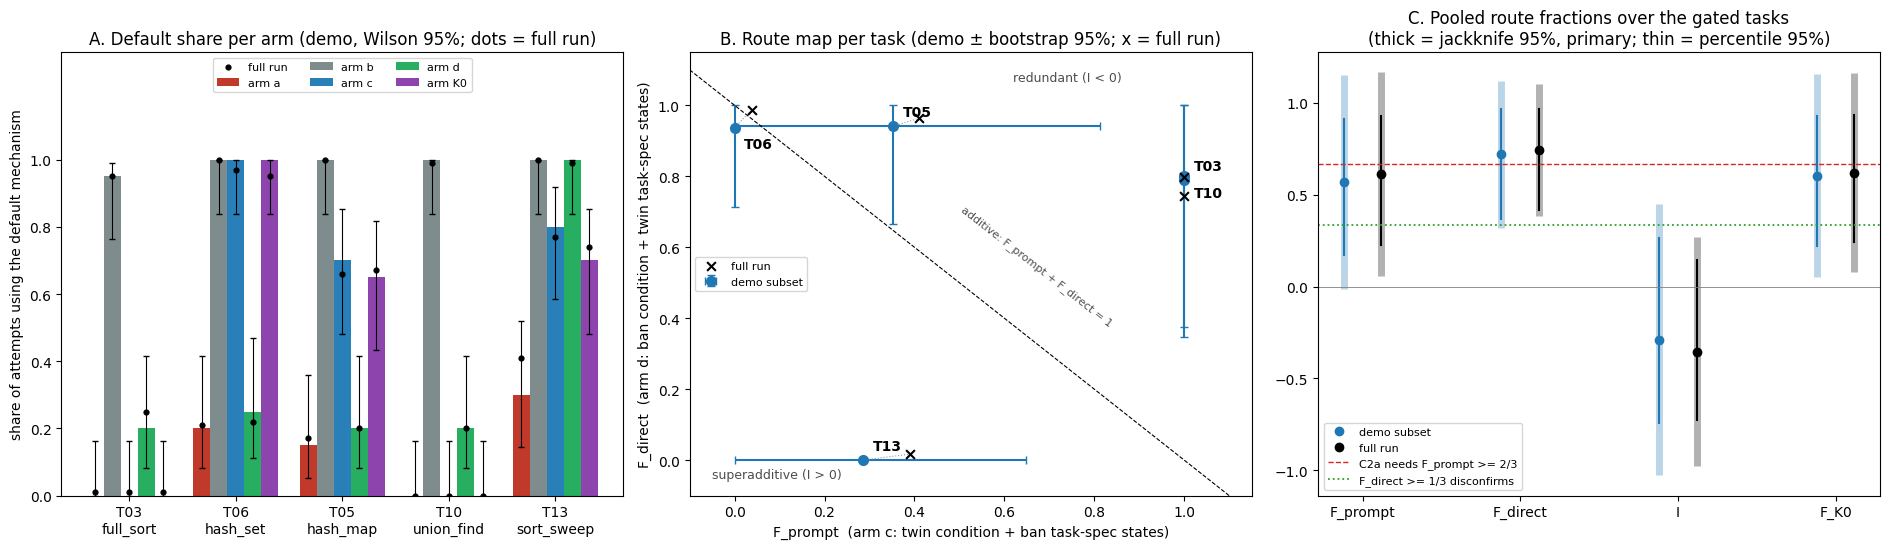

In [25]:
# Figure 1: (A) default share per arm, (B) per-task route map, (C) pooled route fractions vs the C2a thresholds
COL = {"a": "#c0392b", "b": "#7f8c8d", "c": "#2980b9", "d": "#27ae60", "K0": "#8e44ad"}
fig, axes = plt.subplots(1, 3, figsize=(19, 5.6))

# A. default share per task x arm (demo bars with Wilson 95% intervals; black dots = full run)
ax = axes[0]
x = np.arange(len(gated))
wd = 0.16
for j, a in enumerate(ARMS):
    s = np.array([shares[t][a]["s"] for t in gated])
    lo = np.array([shares[t][a]["ci95"][0] for t in gated])
    hi = np.array([shares[t][a]["ci95"][1] for t in gated])
    xs = x + (j - 2) * wd
    ax.bar(xs, s, wd, color=COL[a], label=f"arm {a}", yerr=[np.clip(s - lo, 0, None), np.clip(hi - s, 0, None)],
           capsize=2, error_kw={"lw": 0.8})
    ax.scatter(xs, [ref["shares"][t][a]["s"] for t in gated], color="k", s=12, zorder=3,
               label="full run" if j == 0 else None)
ax.set_xticks(x, [f"{t}\n{default_of(t)}" for t in gated])
ax.set_yticks(np.linspace(0, 1, 6))
ax.set_ylim(0, 1.32)
ax.set_ylabel("share of attempts using the default mechanism")
ax.set_title("A. Default share per arm (demo, Wilson 95%; dots = full run)")
ax.legend(fontsize=8, ncol=3, loc="upper center")

# B. route map: F_prompt vs F_direct per task (demo with template->slot bootstrap 95%; x = full run)
ax = axes[1]
for i, t in enumerate(gated):
    p, d = route["per_task"][t]["F_prompt"], route["per_task"][t]["F_direct"]
    xe = np.clip([[p["point"] - p["ci95"][0]], [p["ci95"][1] - p["point"]]], 0, None)
    ye = np.clip([[d["point"] - d["ci95"][0]], [d["ci95"][1] - d["point"]]], 0, None)
    ax.errorbar(p["point"], d["point"], xerr=xe, yerr=ye, fmt="o", ms=7, capsize=3, color="C0",
                label="demo subset" if i == 0 else None)
    fp, fdir = ref["C2a"]["per_task"][t]["F_prompt"]["point"], ref["C2a"]["per_task"][t]["F_direct"]["point"]
    ax.plot([p["point"], fp], [d["point"], fdir], color="0.6", lw=0.8, ls=":")
    ax.scatter(fp, fdir, marker="x", color="k", s=40, zorder=3, label="full run" if i == 0 else None)
    ax.annotate(t, (p["point"], d["point"]), xytext=(7, 7 if i % 2 == 0 else -15), textcoords="offset points",
                fontsize=10, fontweight="bold")
ax.plot([-0.1, 1.15], [1.1, -0.15], "k--", lw=0.8)
ax.text(0.62, 1.07, "redundant (I < 0)", fontsize=9, color="0.3")
ax.text(-0.05, -0.05, "superadditive (I > 0)", fontsize=9, color="0.3")
ax.text(0.50, 0.38, "additive: F_prompt + F_direct = 1", fontsize=8, color="0.3", rotation=-38)
ax.set_xlim(-0.1, 1.15)
ax.set_ylim(-0.1, 1.15)
ax.set_xlabel("F_prompt  (arm c: twin condition + ban task-spec states)")
ax.set_ylabel("F_direct  (arm d: ban condition + twin task-spec states)")
ax.set_title("B. Route map per task (demo ± bootstrap 95%; x = full run)")
ax.legend(fontsize=8, loc="center left")

# C. pooled fractions (ratio of sums over the gated tasks) with the jackknife (primary) and percentile intervals
ax = axes[2]
qs = ["F_prompt", "F_direct", "I", "F_K0"]
for src, R, dx, col in (("demo subset", route, -0.12, "C0"), ("full run", ref["C2a"], 0.12, "k")):
    for i, kk in enumerate(qs):
        ax.plot([i + dx] * 2, R["intervals"][kk]["jackknife"], color=col, lw=5, alpha=0.3, solid_capstyle="butt")
        ax.plot([i + dx] * 2, R["intervals"][kk]["percentile"], color=col, lw=1.5)
        ax.plot(i + dx, R["point"][kk], "o", color=col, label=src if i == 0 else None)
ax.axhline(THRESHOLDS["F_confirm"], color="C3", ls="--", lw=1, label="C2a needs F_prompt >= 2/3")
ax.axhline(THRESHOLDS["F_direct_disconfirm"], color="C2", ls=":", lw=1.3, label="F_direct >= 1/3 disconfirms")
ax.axhline(0, color="0.5", lw=0.6)
ax.set_xticks(range(len(qs)), qs)
ax.set_title("C. Pooled route fractions over the gated tasks\n(thick = jackknife 95%, primary; thin = percentile 95%)")
ax.legend(fontsize=8, loc="lower left")
fig.tight_layout()
plt.show()

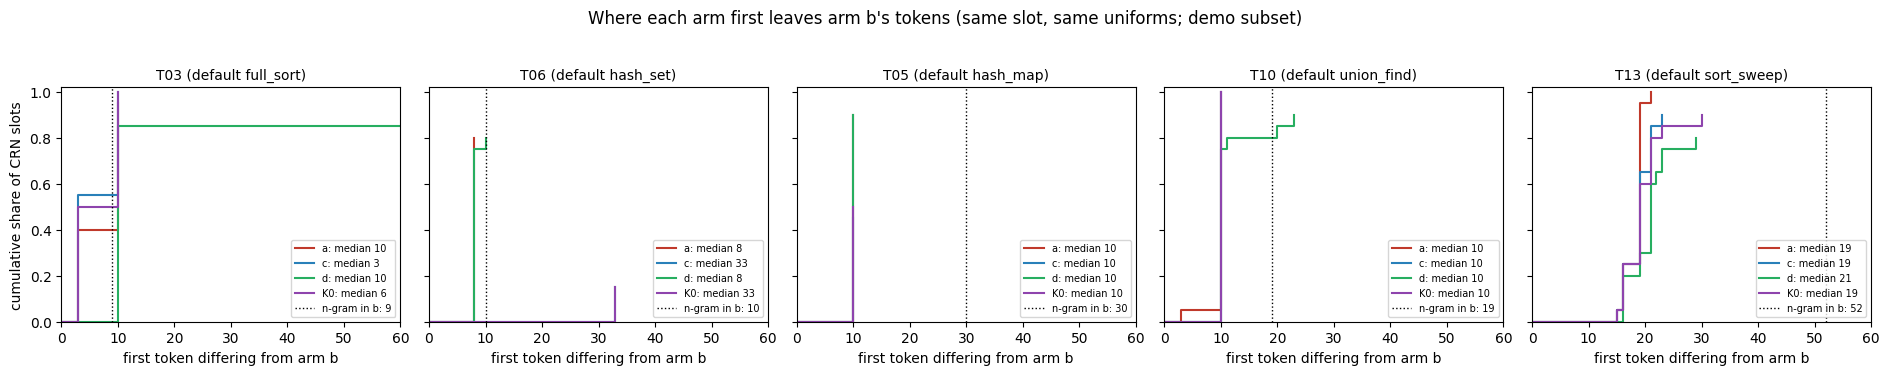

total notebook runtime: 17s


In [26]:
# Figure 2: where in the program each arm first leaves arm b's tokens (CRN first divergence, per gated task)
fig, axes = plt.subplots(1, len(gated), figsize=(3.8 * len(gated), 3.6), sharey=True)
axes = np.atleast_1d(axes)
for ax, t in zip(axes, gated):
    for X in ("a", "c", "d", "K0"):
        fd = crn[t]["first_divergence"].get(X)
        if not fd or not fd["values"]:
            continue
        v = np.sort(fd["values"])
        n = fd["n_diverged"] + fd["n_identical_to_b"]  # slots identical to arm b never diverge
        ax.step(np.concatenate([[0], v]), np.arange(len(v) + 1) / n, where="post", color=COL[X],
                label=f"{X}: median {fd['median']:.0f}")
    m = crn[t]["ngram_first_occurrence_in_b"]["median"]
    if m is not None:
        ax.axvline(m, color="k", ls=":", lw=1, label=f"n-gram in b: {m:.0f}")
    ax.set_xlim(0, 60)
    ax.set_ylim(0, 1.02)
    ax.set_title(f"{t} (default {default_of(t)})", fontsize=10)
    ax.set_xlabel("first token differing from arm b")
    ax.legend(fontsize=7, loc="lower right")
axes[0].set_ylabel("cumulative share of CRN slots")
fig.suptitle("Where each arm first leaves arm b's tokens (same slot, same uniforms; demo subset)", y=1.03)
fig.tight_layout()
plt.show()
print(f"total notebook runtime: {time.time() - T_START:.0f}s")

## Takeaways

The 20-slot demo subset reproduces the full run's numbers and verdicts.

- **The ban works on only 5 of the 12 bench tasks** (the gate), so the route question is asked only where there is an effect to explain.
- **No single route carries the ban.** Pooled over the gated tasks, both routes carry a large share of it:

  | | F_prompt | F_direct | I |
  |---|--:|--:|--:|
  | demo subset | 0.57 | 0.72 | −0.29 |
  | full run | 0.61 | 0.74 | −0.36 |

  The pre-registered claim C2a ("the prompt route carries at least 2/3 of the ban") is **disconfirmed** in both, under the jackknife, percentile and BCa intervals.
- **The mechanism is task-dependent** (route map, panel B).
  - On T03 and T10 either route alone suffices (redundant, I < 0).
  - On T05 and T06 the generated tokens must read the ban text itself: arm d reproduces the ban, while arms c and K0 do not.
  - On T13 both routes are needed (superadditive, I > 0).
- **The ban takes effect at the opening of the function body.** Under common random numbers, arms a and d leave arm b's tokens at a median of token 8–10 on four tasks and 19–21 on T13, whose shared `if not intervals` guard comes first. That is at or before the first occurrence of the default's distinctive n-gram in arm b (tokens 9–52).
- **Vetoing the default's surface n-gram is not the same as banning it.** C2c is **inconclusive** in both the demo and the full run: hit fraction 0.80, ρ(V_t, F_direct) = −0.34, permutation p ≈ 0.30. The frozen n-gram rule picks zero-collateral identifier or structural tokens such as `' set'` and `' find'`, and the model simply renames or re-tokenises around them.

**Scaling up.** The demo uses 20 of the 100 CRN slots per task and arm, and the resampling sizes in the configuration cell are already the original ones. The full analysis needs the GPU stage (`method.py gpu`: Qwen3-8B bf16, about 1.8 GPU-hours on an L4; see the artifact's `README.md`). To run it, point `load_rows()` at the resulting `data/samples.jsonl` and set `N_SLOTS = 20`.